# Economic resilience of Ecuador's economy — resistance, recovery, diversification, composition

**The question.** The Price decomposition showed that during COVID Quito took the *hardest transmission hit* (its incumbent firms' sales collapsed the most) and yet *carried the positive selection* (its firm base held while small-parish firm formation collapsed). That is not one resilience fact but two — so "is Quito more economically resilient than the rest?" needs resilience broken into measurable pieces. Following the regional-resilience literature (Martin 2012; Martin & Sunley 2015), we separate:

- **resistance** — how hard a unit falls when the shock hits,
- **recovery** — how fast it climbs back,
- and we test the leading *explanation*: a **diversified, flexible** economic-activity mix (many CIIU sections, none dominant) should absorb shocks better than a one-industry economy.

**The three framings computed here:**

1. **STEP B — resistance & recovery indices** from monthly trailing-12-month real sales and firm stocks: trough depth, months-to-recovery, and Martin's sensitivity index, per unit. This turns "Quito seems resilient" into a percentile.
2. **STEP C — sectoral diversification at the pre-shock baseline**: Shannon entropy / effective number of CIIU sections per unit, and its raw correlation with the framing-1 outcomes (with the mechanical size–diversity link shown honestly).
3. **STEP D — Bartik shift-share counterfactual**: each unit's predicted hit given only its 2019 sector mix and national sectoral growth. This splits every unit's outcome into **composition** (being in the right/wrong sectors) and a **unit-specific residual** (out/under-performing its own mix — the closest thing to "flexibility" observable here), then regresses outcomes on diversity, size, composition and province fixed effects.

Scale (`LEVEL` = parish / canton / province) and every timeframe are parameters in STEP A. Data: `firm_revenue_enriched_clean.parquet` (formal SRI firms — see the caveats at the end), deflated to constant-2025 USD.

**Extension (STEPS K–N), on the fine-grained data.** The raw SRI file (`raw data/df_ciuu_dpa.csv`) gives parish × month × CIIU rev-4 *group* (239 codes) with sales **and exact firm counts** (`count_id`). Three added framings: **7** — a data-driven *mega-firm* filter (P99 of baseline sales-per-firm) re-runs the resilience machinery on each unit's “regular economy”, testing whether Quito's hard fall (and the diversification null) is really a story about a few giant oil/import balance sheets; **8** — the exact entropy decomposition $H = UV + RV$ splits diversity into *unrelated* (between-section, insurance) and *related* (within-section, adaptation) variety, Frenken et al. (2007), and re-runs the tests with both; **9** — the same identity along the spatial tree tracks whether the national mix lives within or between parishes through the shock.

In [1]:
# ==============================================================================
# STEP A -- setup: monthly real-sales & firm-stock series at a chosen scale
# ------------------------------------------------------------------------------
# Everything downstream runs at LEVEL (parish / canton / province): a unit is
# the first PREFIX digits of cod_parr, so changing one string re-runs the whole
# notebook at another scale. Sales are deflated to constant-2025 USD with the
# yearly IPC factors (one factor per year, as in the decomposition engine).
# The SRI file is missing 2024-11, so the monthly series stops at LAST_YM and
# the annual tables use complete calendar years only (2017-2023).
# Sections: CIIU rev-4 letters A..U; '9' and 'V' are unclassified oddities and
# are kept as their own bucket.
# ==============================================================================
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import paths, style
style.apply()                      # the project's fonts and colours

RES_DIR = paths.RESILIENCE
RES_DIR.mkdir(parents=True, exist_ok=True)

# ---- parameters (scale and every timeframe live here) ------------------------
LEVEL     = "parish"            # "parish" | "canton" | "province"
FIRST_YM  = "2017-01"           # start of the monthly series
LAST_YM   = "2024-10"           # 2024-11 is missing in the SRI file
SHOCK_YM  = "2020-03"           # first lockdown month
TROUGH_BY = "2021-12"           # search for the trough up to here
T0_YEAR   = 2019                # baseline year: shares, diversity, sizes
SHOCK_Y0, SHOCK_Y1 = 2019, 2020 # annual step for sensitivity + shift-share
MIN_FIRMS = 50                  # "big" parishes: >=50 keeps 174 units covering
                                # 94% of 2019 firms (>=10: 460 units but tiny-
                                # parish noise; >=100: 98 units, thin for FE)

PREFIX   = {"parish": 6, "canton": 4, "province": 2}[LEVEL]
FIRST_P  = pd.Period(FIRST_YM, "M");  LAST_P  = pd.Period(LAST_YM, "M")
SHOCK_P  = pd.Period(SHOCK_YM, "M");  TROUGH_P = pd.Period(TROUGH_BY, "M")
BENCH_P  = SHOCK_P - 1                       # last pre-shock month (2020-02)
FULL_YEARS = list(range(2017, 2024))         # complete calendar years

# ---- palette (same as the decomposition notebooks) ----------------------------
CUSTOM_PURPLE = style.PURPLE;  PURPLE_DOT = style.tint(style.PURPLE, 0.6)     # firms / Quito
CUSTOM_ORANGE = style.ORANGE;  ORANGE_DOT = style.tint(style.ORANGE, 0.6)     # sales / Cuenca
CUSTOM_RED    = style.RED;  RED_DOT    = style.tint(style.RED, 0.6)     # COVID / Guayaquil
CUSTOM_GRAY   = style.GREY;  GRAY_DOT   = style.CONTEXT     # neutral / everyone else
CUSTOM_BLUE   = style.BLUE                              # positive pole in bars

SEC_NAME = {"A": "Agriculture", "B": "Mining", "C": "Manufacturing",
            "D": "Electricity/gas", "E": "Water/waste", "F": "Construction",
            "G": "Trade", "H": "Transport", "I": "Accommodation & food",
            "J": "Information & comm.", "K": "Finance", "L": "Real estate",
            "M": "Professional/scientific", "N": "Admin. services",
            "O": "Public administration", "P": "Education", "Q": "Health",
            "R": "Arts & recreation", "S": "Other services",
            "T": "Household employers", "U": "Extraterritorial",
            "V": "Unclassified", "9": "Unclassified"}

# ---- load + deflate -----------------------------------------------------------
df = pd.read_parquet(paths.FIRM_REVENUE_PARQUET,
                     columns=["anio", "mes", "cod_ciuu4", "cod_parr",
                              "total_sales", "total_firms"])
df["year"] = df["anio"].astype(int)
ipc = pd.read_csv(paths.IPC_CSV)
ipc.columns = ["year", "factor"]                       # header is Spanish ("año")
df["real_sales"] = df["total_sales"] * df["year"].map(dict(zip(ipc["year"], ipc["factor"])))
df["ym"]   = pd.PeriodIndex(df["anio"] + "-" + df["mes"], freq="M")
df["unit"] = df["cod_parr"].str[:PREFIX]
df = df[(df["ym"] >= FIRST_P) & (df["ym"] <= LAST_P)]

# ---- monthly series per unit: sales are a flow, the firm count a stock ---------
months = pd.period_range(FIRST_P, LAST_P, freq="M")
m = (df.groupby(["unit", "ym"])
       .agg(sales=("real_sales", "sum"), firms=("total_firms", "sum")))
SALES_M = m["sales"].unstack("unit").reindex(months).fillna(0.0)
FIRMS_M = m["firms"].unstack("unit").reindex(months).fillna(0.0)

# trailing 12 months kill the strong seasonality in both series
S12 = SALES_M.rolling(12, min_periods=12).sum()        # flow  -> 12m total
F12 = FIRMS_M.rolling(12, min_periods=12).mean()       # stock -> 12m mean

# ---- annual tables (complete years only) ---------------------------------------
ANN_SALES = (df[df["year"].isin(FULL_YEARS)]
             .groupby(["unit", "year"])["real_sales"].sum().unstack("year"))
ANN_FIRMS = pd.DataFrame({y: FIRMS_M.loc[FIRMS_M.index.year == y].mean()
                          for y in FULL_YEARS})
ANN_SALES = ANN_SALES.reindex(ANN_FIRMS.index).fillna(0.0)

# ---- who is in: a real baseline presence, alive across the shock step ----------
alive = ((ANN_FIRMS[T0_YEAR] >= MIN_FIRMS)
         & (ANN_SALES[SHOCK_Y0] > 0) & (ANN_SALES[SHOCK_Y1] > 0))
KEEP = sorted(alive.index[alive])
S12, F12 = S12[KEEP], F12[KEEP]
ANN_SALES, ANN_FIRMS = ANN_SALES.loc[KEEP], ANN_FIRMS.loc[KEEP]

# ---- names (dpa.xlsx has Galápagos; the shapefile does not) ---------------------
dpa = pd.read_excel(paths.DPA_XLSX, dtype=str, header=None)
dpa = dpa[dpa[1].astype(str).str.match(r"^\d{6}$", na=False)]
NAME = {6: {c: f"{p.title().strip()} ({k.title().strip()})"
            for c, k, p in zip(dpa[1], dpa[5], dpa[7])},
        4: {c[:4]: k.title().strip() for c, k in zip(dpa[1], dpa[5])},
        2: {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}}[PREFIX]
def uname(code):
    return NAME.get(code, code)

# the three metro units; at canton/province level the label means "the unit
# that contains this metro" (e.g. province 17 = Pichincha for Quito)
METROS  = {p[:PREFIX]: lab for p, lab in
           [("170150", "Quito"), ("090150", "Guayaquil"), ("010150", "Cuenca")]}
METRO_C = dict(style.CITY)

# shared scatter helpers: dot area from the initial firm share, and one routine
# that colours + labels the metros with per-metro offsets so labels never collide
def dot_area(p):
    'marker area (pt^2) from an initial firm share; Quito (~0.26) -> ~400'
    return 1.5e3 * p + 3

METRO_DXY = {"Quito": (8, 6, "left"), "Guayaquil": (8, -14, "left"),
             "Cuenca": (-8, 8, "right")}

def mark_metros(ax, xs, ys, p):
    'highlight + label the metro dots on a scatter of unit-indexed series'
    for u, lab in METROS.items():
        if u in xs.index and pd.notna(xs.get(u)) and pd.notna(ys.get(u)):
            ax.scatter(xs[u], ys[u], s=dot_area(p[u]) + 20, color=METRO_C[lab],
                       edgecolor="white", lw=0.8, zorder=3)
            dx, dy, ha = METRO_DXY[lab]
            ax.annotate(lab, (xs[u], ys[u]), textcoords="offset points",
                        xytext=(dx, dy), ha=ha, fontsize=8.5, color="0.2")

print(f"level = {LEVEL}: {len(KEEP)} units kept of {ANN_FIRMS.shape[0]} "
      f"(baseline mean stock >= {MIN_FIRMS} firms in {T0_YEAR}, "
      f"positive sales {SHOCK_Y0} and {SHOCK_Y1})")
print(f"monthly span {FIRST_P}..{LAST_P}; trailing-12m series valid from "
      f"{FIRST_P + 11}; benchmark month {BENCH_P}")
print(f"kept units cover {ANN_FIRMS[T0_YEAR].sum():,.0f} firms and "
      f"${ANN_SALES[T0_YEAR].sum()/1e9:,.1f}B real sales in {T0_YEAR}")

level = parish: 174 units kept of 174 (baseline mean stock >= 50 firms in 2019, positive sales 2019 and 2020)
monthly span 2017-01..2024-10; trailing-12m series valid from 2017-12; benchmark month 2020-02
kept units cover 134,601 firms and $137.4B real sales in 2019


## FRAMING 1 — resistance and recovery (STEP B)

Both indices come from the **trailing-12-month** series (sum for sales, a flow; mean for the firm count, a stock), which removes the strong seasonality documented in the seasonality notebook. The price of that smoothing is timing: a 12-month window reacts with up to ~11 months of delay, so troughs land around early-2021 even though the worst months were Apr–Jun 2020 — depths are unaffected, and recovery is measured against the same smoothed benchmark.

For each unit $i$, with benchmark $B_i$ = the trailing-12m value in the last pre-shock month (Feb-2020):

- **Resistance** (trough depth, log points): $\;\mathcal{R}_i=\ln\dfrac{\min_{t\,\in\,[\text{Mar-20},\ \text{TROUGH\_BY}]}X^{12m}_i(t)}{B_i}$. More negative = fell harder; $\mathcal{R}_i\ge 0$ means the unit never fell below its pre-shock level at all (common for firm stocks).
- **Recovery** (months): the first month at/after the trough where $X^{12m}_i \ge B_i$, counted from Mar-2020. Zero if the unit never fell; **NaN = censored** (not back by `LAST_YM`) — censored counts are reported, and recovery percentiles ignore censored units (so they flatter slow recoverers slightly).
- **Sensitivity** (Martin 2012): $\;\beta_i=\dfrac{\Delta\ln(\text{annual real sales})_i^{2019\to20}}{\Delta\ln(\text{annual real sales})_{EC}^{2019\to20}}$ — $\beta>1$ hit harder than the country, $\beta<0$ grew against the tide.

Sales and firms are computed separately on purpose: the decomposition said Quito's *sales* fell hard (transmission) while its *firm base* held (selection). Here that should appear as: bad `res_sales`, good `res_firms` — resilience on the extensive margin, fragility on the intensive one.

In [2]:
# ==============================================================================
# STEP B -- FRAMING 1: resistance and recovery, unit by unit
# ------------------------------------------------------------------------------
# Produces `res`: one row per unit with trough depths (log points), recovery
# months, Martin sensitivity, and baseline sizes. 0 recovery = never fell;
# NaN recovery = censored (not back by LAST_YM).
# ==============================================================================
B_S, B_F = S12.loc[BENCH_P], F12.loc[BENCH_P]

def trough_and_recovery(X12, bench):
    """Per unit: trough depth of the trailing-12m series in log points (>= 0 if
    it never fell below the benchmark), the trough month, and months from the
    shock until the series is back at the benchmark (0 never fell, NaN censored)."""
    win = X12.loc[SHOCK_P:TROUGH_P]
    trough, t_tr = win.min(), win.idxmin()
    depth = np.log(trough.where(trough > 0) / bench)
    rec = {}
    for u in X12.columns:
        if trough[u] >= bench[u]:
            rec[u] = 0.0                          # never fell below the benchmark
            continue
        back = X12.loc[t_tr[u]:, u]
        back = back[back >= bench[u]]
        rec[u] = float((back.index[0] - SHOCK_P).n) if len(back) else np.nan
    return depth, t_tr, pd.Series(rec)

res_s, tr_s, rec_s = trough_and_recovery(S12, B_S)
res_f, tr_f, rec_f = trough_and_recovery(F12, B_F)

# Martin sensitivity index on the annual shock step (unit vs country)
dln_s  = np.log(ANN_SALES[SHOCK_Y1] / ANN_SALES[SHOCK_Y0])
dln_f  = np.log(ANN_FIRMS[SHOCK_Y1] / ANN_FIRMS[SHOCK_Y0])
dln_EC = np.log(ANN_SALES[SHOCK_Y1].sum() / ANN_SALES[SHOCK_Y0].sum())
beta_s = dln_s / dln_EC

res = pd.DataFrame({
    "name":   [uname(u) for u in KEEP],
    "firms0":  ANN_FIRMS[T0_YEAR],
    "sales0":  ANN_SALES[T0_YEAR],
    "p0":      ANN_FIRMS[T0_YEAR] / ANN_FIRMS[T0_YEAR].sum(),   # firm share
    "res_sales": res_s, "trough_sales": tr_s.astype(str), "rec_sales": rec_s,
    "res_firms": res_f, "trough_firms": tr_f.astype(str), "rec_firms": rec_f,
    "dln_sales": dln_s, "beta_sales": beta_s, "dln_firms": dln_f,
}, index=pd.Index(KEEP, name="unit"))

print(f"Ecuador {SHOCK_Y0}->{SHOCK_Y1}: annual real sales {dln_EC:+.3f} log pts")
print(f"censored recoveries (not back by {LAST_P}): "
      f"sales {int(res['rec_sales'].isna().sum())}, "
      f"firms {int(res['rec_firms'].isna().sum())} of {len(res)} units")
print(f"never fell below benchmark: sales {int((res['res_sales'] >= 0).sum())}, "
      f"firms {int((res['res_firms'] >= 0).sum())}")
print("\nmedians:", res[["res_sales", "rec_sales", "res_firms", "rec_firms"]]
      .median().round(3).to_dict())

print("\n--- the metros ---")
mcols = ["name", "res_sales", "rec_sales", "res_firms", "rec_firms", "beta_sales"]
print(res.loc[list(METROS), mcols].round(3).to_string())

print("\npercentile among all units (100 = most resistant / fastest back):")
for u, lab in METROS.items():
    parts = []
    for c in ["res_sales", "res_firms"]:                       # higher = better
        parts.append(f"{c} {100 * (res[c] < res.loc[u, c]).mean():3.0f}%")
    for c in ["rec_sales", "rec_firms"]:                       # fewer months = better
        v, ok = res.loc[u, c], res[c].dropna()
        parts.append(f"{c} {100 * (ok > v).mean():3.0f}%" if pd.notna(v)
                     else f"{c} censored")
    print(f"  {lab:10s}  " + "   ".join(parts))

show = ["name", "res_sales", "rec_sales", "beta_sales", "firms0"]
print("\nhardest-hit units (sales trough):")
print(res.sort_values("res_sales")[show].head(10).round(3).to_string())
print("\nmost resistant units (sales trough):")
print(res.sort_values("res_sales")[show].tail(10).round(3).to_string())

Ecuador 2019->2020: annual real sales -0.148 log pts
censored recoveries (not back by 2024-10): sales 6, firms 0 of 174 units
never fell below benchmark: sales 6, firms 100

medians: {'res_sales': -0.137, 'rec_sales': 15.0, 'res_firms': 0.003, 'rec_firms': 0.0}

--- the metros ---
                                                                                                             name  res_sales  rec_sales  res_firms  rec_firms  beta_sales
unit                                                                                                                                                                     
170150  Quito Distrito Metropolitano, Cabecera Cantonal, Capital Provincial Y De La Republica Del Ecuador (Quito)     -0.250       25.0      0.008        0.0       1.531
090150                                                                                      Guayaquil (Guayaquil)     -0.135       17.0      0.006        0.0       0.759
010150                                

saved -> results/resilience/trajectories_parish.png


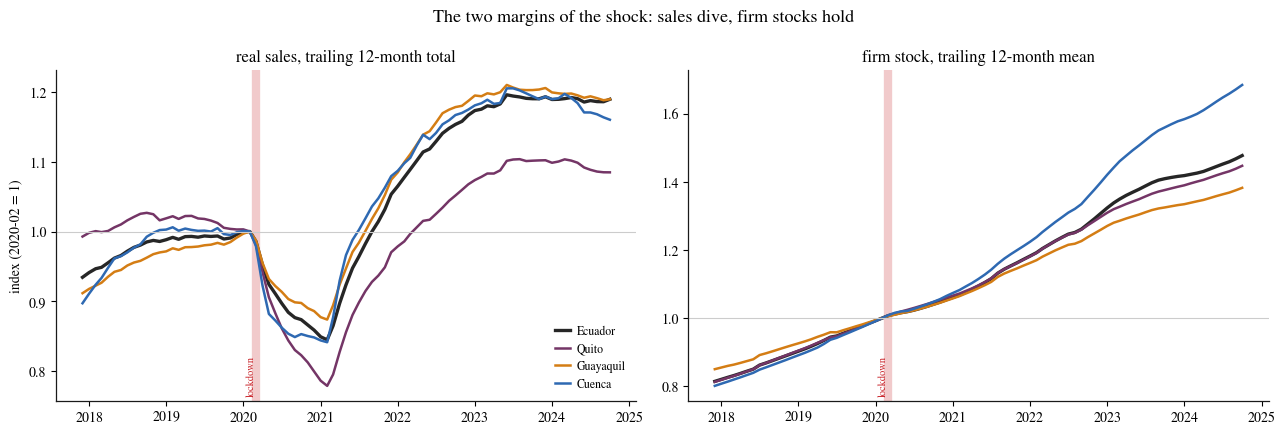

saved -> results/resilience/resistance_vs_recovery_parish.png


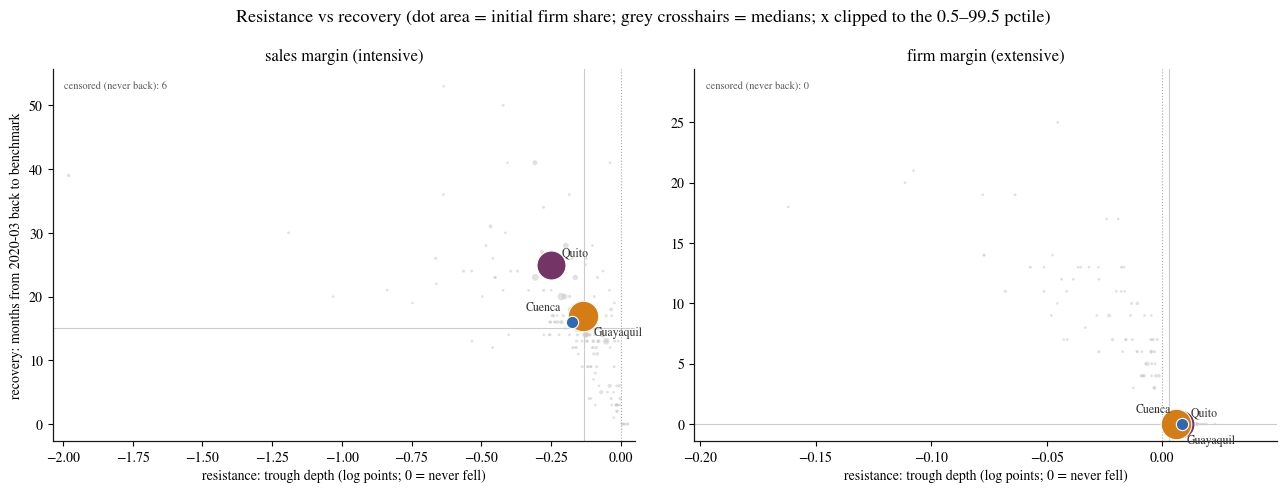

In [3]:
# ==============================================================================
# STEP B (cont.) -- the two framing-1 figures
# ------------------------------------------------------------------------------
# 1) trajectories: trailing-12m real sales and firm stock, indexed to the
#    pre-shock benchmark (=1), Ecuador vs the three metros. The two margins of
#    resilience in one glance: sales dive and crawl back, firm stocks barely dip.
# 2) the resistance x recovery plane, one panel per margin: every unit a dot
#    (area = initial firm share), median crosshairs, metros named. Bottom-left
#    of the crosshairs = fell hard AND slow back = least resilient quadrant.
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4), sharex=True)
for ax, (X12, ttl) in zip(axes, [(S12, "real sales, trailing 12-month total"),
                                 (F12, "firm stock, trailing 12-month mean")]):
    X12 = X12.dropna()                 # first 11 months: the 12m window is empty
    x = X12.index.to_timestamp()
    ec = X12.sum(axis=1)
    ax.plot(x, (ec / ec.loc[BENCH_P]).values, color="0.15", lw=2.4, label="Ecuador")
    for u, lab in METROS.items():
        s = X12[u] / X12.loc[BENCH_P, u]
        ax.plot(x, s.values, color=METRO_C[lab], lw=1.8, label=lab)
    ax.axhline(1.0, color="0.8", lw=0.8)
    ax.axvline(SHOCK_P.to_timestamp(), color=RED_DOT, lw=6, alpha=0.6, zorder=0)
    ax.annotate("lockdown", xy=(SHOCK_P.to_timestamp(), 0.02),
                xycoords=("data", "axes fraction"), fontsize=7.5,
                color=CUSTOM_RED, ha="right", rotation=90)
    ax.set_title(ttl, fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel(f"index ({BENCH_P} = 1)", fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, loc="lower right",
               handlelength=1.2, handletextpad=0.6)
fig.suptitle("The two margins of the shock: sales dive, firm stocks hold", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"trajectories_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"trajectories_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"trajectories_{LEVEL}.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
for ax, (xc, yc, ttl) in zip(axes, [
        ("res_sales", "rec_sales", "sales margin (intensive)"),
        ("res_firms", "rec_firms", "firm margin (extensive)")]):
    d = res.dropna(subset=[xc, yc])
    ax.scatter(d[xc], d[yc], s=dot_area(d["p0"]), color=GRAY_DOT,
               alpha=0.55, lw=0)
    ax.axvline(d[xc].median(), color="0.8", lw=0.8)
    ax.axhline(d[yc].median(), color="0.8", lw=0.8)
    ax.axvline(0, color="0.65", lw=0.8, ls=":")
    mark_metros(ax, d[xc], d[yc], d["p0"])
    lo, hi = np.nanpercentile(d[xc], [0.5, 99.5])
    ax.set_xlim(lo - 0.03, hi + 0.03)          # display clip; table keeps all
    n_cens = int(res[yc].isna().sum())
    ax.text(0.02, 0.97, f"censored (never back): {n_cens}",
            transform=ax.transAxes, va="top", fontsize=7.5, color="0.35")
    ax.set_title(ttl, fontsize=12)
    ax.set_xlabel("resistance: trough depth (log points; 0 = never fell)", fontsize=10)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel(f"recovery: months from {SHOCK_P} back to benchmark", fontsize=10)
fig.suptitle("Resistance vs recovery (dot area = initial firm share; grey "
             "crosshairs = medians; x clipped to the 0.5–99.5 pctile)", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"resistance_vs_recovery_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"resistance_vs_recovery_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"resistance_vs_recovery_{LEVEL}.png")
plt.show()

## FRAMING 2 — sectoral diversification at the baseline (STEP C)

For each unit, take its baseline-year (`T0_YEAR`, 2019 by default) composition across CIIU sections $a$ (shares $s_a$ of real sales, and separately of firms) and compute

$$H_i=-\sum_a s_{ia}\ln s_{ia},\qquad N^{\text{eff}}_i=e^{H_i},\qquad \text{HHI}_i=\sum_a s_{ia}^2 .$$

$N^{\text{eff}}$ is the **effective number of sections**: a parish with all sales in one section has $N^{\text{eff}}=1$; one spread evenly over five sections has $N^{\text{eff}}=5$. It is the readable version of entropy and what the figures use (HHI is kept in the table as the familiar inverse).

The hypothesis being tested: **diversified units resist better and recover faster** — the portfolio argument. Two honesty requirements, both handled below:

1. **Diversity is mechanically tied to size** — a unit with 12 firms *cannot* occupy 15 sections. The first panel shows the size–diversity relation directly, and the correlation table reports each diversity–resilience correlation twice: raw, and partialling out $\ln(\text{firms}_0)$. Only the partial version speaks about diversification rather than bigness.
2. **Correlation here is composition-blind** — a diverse unit may still be diverse *in the wrong sectors*. Separating "right sectors" from "diverse per se" is exactly what the shift-share in FRAMING 3 does; this step only establishes whether the raw pattern exists at all.

diversity vs resilience  (res_*: + = diverse fell LESS;  rec_*: - = diverse recovered FASTER)
 diversity   outcome   n  spearman  pearson  pearson_sizectrl
neff_sales res_sales 174    -0.150   -0.007            -0.077
neff_sales rec_sales 168     0.054    0.110             0.077
neff_sales res_firms 174     0.199    0.106            -0.063
neff_sales rec_firms 174    -0.238   -0.209            -0.017
neff_firms res_sales 174     0.096    0.216             0.194
neff_firms rec_sales 168     0.035   -0.035            -0.125
neff_firms res_firms 174     0.268    0.181            -0.025
neff_firms rec_firms 174    -0.315   -0.258            -0.018

--- the metros ---
                                                                                                             name  neff_sales  neff_firms  hhi_sales    firms0
unit                                                                                                                                                          
170150  Qu

saved -> results/resilience/diversity_parish.png


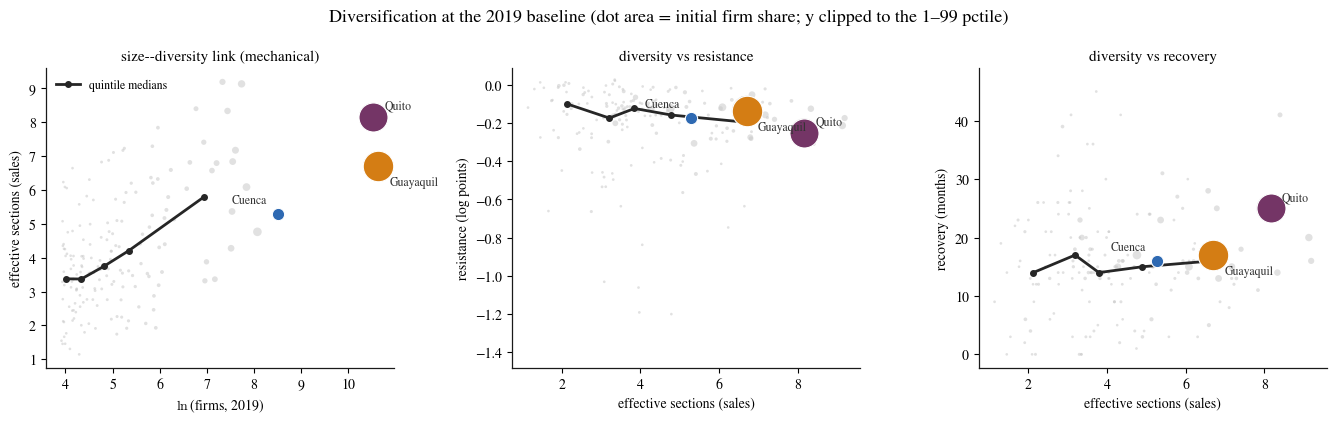

In [4]:
# ==============================================================================
# STEP C -- FRAMING 2: diversity metrics + their correlation with framing 1
# ------------------------------------------------------------------------------
# `div`: per unit, entropy H, effective sections N_eff, and HHI -- computed on
# sales shares AND firm shares at T0_YEAR. Firm shares per section = the year's
# summed monthly stocks / 12 (absent months count as zero firms).
# Correlations: Spearman + Pearson raw, and Pearson partialling out ln(firms0).
# ==============================================================================
sec19_sales = (df[df["year"] == T0_YEAR]
               .groupby(["unit", "cod_ciuu4"])["real_sales"].sum()
               .unstack(fill_value=0.0).reindex(KEEP).fillna(0.0))
sec19_firms = (df[df["year"] == T0_YEAR]
               .groupby(["unit", "cod_ciuu4"])["total_firms"].sum()
               .unstack(fill_value=0).reindex(KEEP).fillna(0.0) / 12.0)

def entropy_metrics(comp, tag):
    'Shannon entropy, effective section count and HHI of one composition table.'
    sh = comp.div(comp.sum(axis=1), axis=0)
    H = -(sh * np.log(sh.where(sh > 0))).sum(axis=1)      # 0*ln0 counted as 0
    return pd.DataFrame({f"H_{tag}": H, f"neff_{tag}": np.exp(H),
                         f"hhi_{tag}": (sh ** 2).sum(axis=1)})

div = entropy_metrics(sec19_sales, "sales").join(entropy_metrics(sec19_firms, "firms"))
log_firms0 = np.log(res["firms0"])

from scipy import stats as sps

def partial_r(x, y, z):
    'Pearson r between x and y after removing a linear control z from both.'
    m = x.notna() & y.notna() & z.notna()
    x, y, z = x[m], y[m], z[m]
    A = np.c_[np.ones(len(z)), z]
    rx = x - A @ np.linalg.lstsq(A, x, rcond=None)[0]
    ry = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return float(np.corrcoef(rx, ry)[0, 1])

rows = []
for tag in ["sales", "firms"]:
    neff = div[f"neff_{tag}"]
    for metric in ["res_sales", "rec_sales", "res_firms", "rec_firms"]:
        y, m_ = res[metric], res[metric].notna()
        rows.append(dict(
            diversity=f"neff_{tag}", outcome=metric, n=int(m_.sum()),
            spearman=float(sps.spearmanr(neff[m_], y[m_]).statistic),
            pearson=float(sps.pearsonr(neff[m_], y[m_]).statistic),
            pearson_sizectrl=partial_r(neff, y, log_firms0)))
corr = pd.DataFrame(rows)
print("diversity vs resilience  (res_*: + = diverse fell LESS;  rec_*: - = diverse "
      "recovered FASTER)")
print(corr.round(3).to_string(index=False))

print("\n--- the metros ---")
print(div.join(res[["name", "firms0"]]).loc[list(METROS),
      ["name", "neff_sales", "neff_firms", "hhi_sales", "firms0"]]
      .round(2).to_string())
print("\nmost diversified units (sales N_eff):")
print(div.join(res["name"]).sort_values("neff_sales", ascending=False)
      [["name", "neff_sales", "neff_firms"]].head(8).round(2).to_string())

def binned_median(x, y, q=5):
    'median y within quantile bins of x (an honest non-parametric trend line)'
    b = pd.qcut(x, q, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(b, observed=True)
    return g["x"].median().values, g["y"].median().values

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
panels = [(log_firms0, div["neff_sales"], r"$\ln$(firms, " + str(T0_YEAR) + ")",
           "effective sections (sales)", "size--diversity link (mechanical)", False),
          (div["neff_sales"], res["res_sales"], "effective sections (sales)",
           "resistance (log points)", "diversity vs resistance", True),
          (div["neff_sales"], res["rec_sales"], "effective sections (sales)",
           "recovery (months)", "diversity vs recovery", True)]
for ax, (x, y, xl, yl, ttl, clip_y) in zip(axes, panels):
    m_ = x.notna() & y.notna()
    ax.scatter(x[m_], y[m_], s=dot_area(res.loc[m_[m_].index, "p0"]),
               color=GRAY_DOT, alpha=0.55, lw=0)
    bx, by = binned_median(x[m_], y[m_])
    ax.plot(bx, by, color="0.15", lw=2.0, marker="o", ms=4, label="quintile medians")
    mark_metros(ax, x[m_], y[m_], res["p0"])
    if clip_y:                                 # display clip; table keeps all
        lo, hi = np.nanpercentile(y[m_], [1, 99])
        pad = 0.05 * (hi - lo)
        ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(xl, fontsize=10); ax.set_ylabel(yl, fontsize=10)
    ax.set_title(ttl, fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle(f"Diversification at the {T0_YEAR} baseline "
             "(dot area = initial firm share; y clipped to the 1–99 pctile)",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"diversity_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"diversity_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"diversity_{LEVEL}.png")
plt.show()

## FRAMING 3 — the Bartik shift-share: composition vs unit-specific resilience (STEP D)

A unit can fall hard for two very different reasons: it was **in the wrong sectors** (composition — accommodation and food service collapsed everywhere), or it **under-performed its own sectors** (something local). The shift-share separates them. With $w_{ia}$ = unit $i$'s share of section $a$ in its `SHOCK_Y0` (2019) real sales and $g_{a,-i}$ = the **national** log growth of section $a$ over the `SHOCK_Y0`→`SHOCK_Y1` step (2019→20) computed *leaving unit $i$ out* (Quito is ~a quarter of the economy, so leave-one-out is not optional):

$$\underbrace{\Delta\ln y_i}_{\text{actual hit}}=\underbrace{\sum_a w_{ia}\,g_{a,-i}}_{\text{Bartik: predicted by the sector mix alone}}+\underbrace{\varepsilon_i}_{\text{unit-specific residual}}$$

**The residual $\varepsilon_i$ is the money statistic of this framing.** It is the part of the hit that the unit's own composition cannot explain — the closest observable analogue of "flexibility/competitiveness" at this grain. The regression then asks the question the whole notebook builds to:

$$\Delta\ln y_i \;(\text{or }\varepsilon_i) \;=\; \alpha+\gamma\,\text{Bartik}_i+\delta\,N^{\text{eff}}_i+\lambda\ln(\text{firms}_0)+\text{province FE}+u_i$$

- If **$\delta>0$** with size, composition and province absorbed: diversification *per se* buffered the shock — your hypothesis survives its hardest test here.
- If $\delta\approx 0$ but the Bartik coefficient carries everything: "diversified places did better" was really "places in the right sectors did better".
- **Quito's verdict** is read off its decomposition line: how much of its (large) hit was its sector mix, and is its residual above or below zero once you account for it?

variance of the actual hit explained by composition alone: 18.3%

--- the metros: actual = composition + own residual (log pts) ---
  Quito      -0.226 = -0.131 (mix) -0.096 (own)
  Guayaquil  -0.112 = -0.158 (mix) +0.046 (own)
  Cuenca     -0.163 = -0.136 (mix) -0.027 (own)


saved -> results/resilience/bartik_parish.png


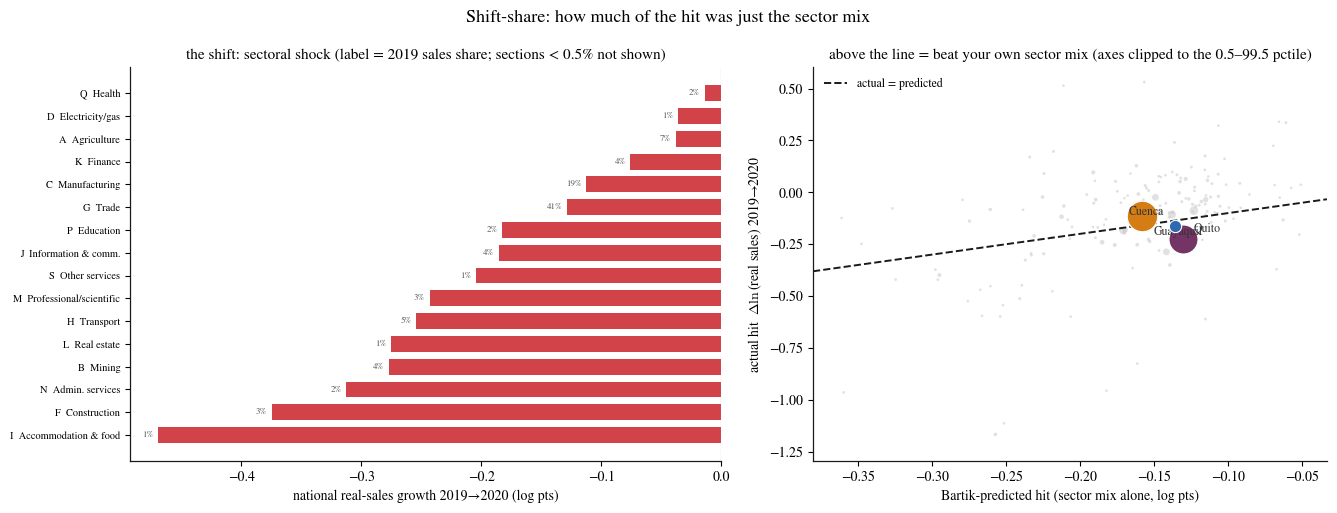


actual hit ~ composition + diversity + size
  n=174  R2=0.517  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  0.1715    0.0815  2.1045  0.0353  0.0118  0.3312
bartik     2.0326    0.3967  5.1237  0.0000  1.2551  2.8101
neff       0.0086    0.0136  0.6363  0.5246 -0.0180  0.0352
log_firms -0.0047    0.0158 -0.2993  0.7647 -0.0356  0.0262

unit-specific residual ~ diversity + size
  n=174  R2=0.370  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  0.0082    0.0635  0.1285  0.8978 -0.1162  0.1325
neff      -0.0015    0.0127 -0.1217  0.9031 -0.0264  0.0234
log_firms  0.0049    0.0161  0.3029  0.7620 -0.0267  0.0364

recovery months ~ composition + diversity + size (censored dropped)
  n=168  R2=0.301  (province FE: yes; HC1 SEs)
             Coef.  Std.Err.       z   P>|z|   [0.025   0.975]
Intercept   5.2029    3.7375  1.3921  0.1639  -2.1225  12.5283
bartik    -47.8676   14.8738 -3.2183

In [5]:
# ==============================================================================
# STEP D -- FRAMING 3: leave-one-out Bartik, the residual, and the regression
# ------------------------------------------------------------------------------
# g_all: national sectoral log growth SHOCK_Y0->SHOCK_Y1 (the "shift").
# bartik_i = sum_a w_ia * g_(a,-i)  with unit i removed from the national growth
# (falls back to g_all, then 0, where a leave-one-out log is undefined).
# residual_i = actual_i - bartik_i.  OLS with HC1 SEs, province FE when the
# level is finer than province. Everything is merged and saved as one CSV.
# ==============================================================================
Y19 = sec19_sales                                      # unit x section, SHOCK_Y0
Y20 = (df[df["year"] == SHOCK_Y1]
       .groupby(["unit", "cod_ciuu4"])["real_sales"].sum()
       .unstack(fill_value=0.0).reindex(KEEP).fillna(0.0))
secs = Y19.columns.union(Y20.columns)
Y19, Y20 = (Y19.reindex(columns=secs, fill_value=0.0),
            Y20.reindex(columns=secs, fill_value=0.0))

S19, S20 = Y19.sum(), Y20.sum()
g_all = np.log(S20.where(S20 > 0) / S19.where(S19 > 0))
num, den = S20 - Y20, S19 - Y19                        # leave-one-out totals
g_loo = np.log(num.where(num > 0) / den.where(den > 0))
g_loo = g_loo.fillna(g_all).fillna(0.0)

w19    = Y19.div(Y19.sum(axis=1), axis=0)
bartik = (w19 * g_loo).sum(axis=1)
actual = res["dln_sales"]                              # same annual step
residual = actual - bartik
comp_share = 1 - residual.var() / actual.var()
print(f"variance of the actual hit explained by composition alone: {comp_share:.1%}")

print("\n--- the metros: actual = composition + own residual (log pts) ---")
for u, lab in METROS.items():
    print(f"  {lab:10s} {actual[u]:+.3f} = {bartik[u]:+.3f} (mix) "
          f"{residual[u]:+.3f} (own)")

# ---- figure: the national shift, and predicted vs actual -----------------------
share19 = S19 / S19.sum()
MIN_SHOW = 0.005                        # bars: sections >= 0.5% of national sales
order = [a for a in g_all.sort_values().index if share19[a] >= MIN_SHOW]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2),
                         gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
cols = [CUSTOM_RED if g_all[a] < 0 else CUSTOM_BLUE for a in order]
ax.barh([f"{a}  {SEC_NAME.get(a, a)}" for a in order],
        [g_all[a] for a in order], color=cols, alpha=0.85, height=0.7)
for k, a in enumerate(order):
    ax.text(g_all[a] + (0.004 if g_all[a] >= 0 else -0.004), k,
            f"{100 * share19[a]:.0f}%", va="center",
            ha="left" if g_all[a] >= 0 else "right", fontsize=6.5, color="0.35")
ax.axvline(0, color="0.6", lw=0.8)
ax.tick_params(axis="y", labelsize=7.5)
ax.set_xlabel(f"national real-sales growth {SHOCK_Y0}→{SHOCK_Y1} (log pts)",
              fontsize=10)
ax.set_title(f"the shift: sectoral shock (label = {SHOCK_Y0} sales share; "
             f"sections < {100 * MIN_SHOW:.1f}% not shown)", fontsize=11)

ax = axes[1]
ax.scatter(bartik, actual, s=dot_area(res["p0"]), color=GRAY_DOT, alpha=0.55, lw=0)
# each axis clips to its own 0.5-99.5 pctile: bartik is much narrower than the
# actual hit (residuals dominate), and squaring the axes would hide that
bx0, bx1 = np.nanpercentile(bartik, [0.5, 99.5])
ay0, ay1 = np.nanpercentile(actual, [0.5, 99.5])
padx, pady = 0.06 * (bx1 - bx0), 0.05 * (ay1 - ay0)
xg = np.linspace(bx0 - padx, bx1 + padx, 2)
ax.plot(xg, xg, color="0.1", lw=1.4, ls="--", label="actual = predicted")
mark_metros(ax, bartik, actual, res["p0"])
ax.set_xlim(bx0 - padx, bx1 + padx)
ax.set_ylim(ay0 - pady, ay1 + pady)            # display clip; table keeps all
ax.set_xlabel("Bartik-predicted hit (sector mix alone, log pts)", fontsize=10)
ax.set_ylabel(f"actual hit  $\\Delta\\ln$(real sales) {SHOCK_Y0}→{SHOCK_Y1}",
              fontsize=10)
ax.set_title("above the line = beat your own sector mix "
             "(axes clipped to the 0.5–99.5 pctile)", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
for a in axes:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
fig.suptitle("Shift-share: how much of the hit was just the sector mix", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"bartik_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"bartik_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"bartik_{LEVEL}.png")
plt.show()

# ---- the regression -------------------------------------------------------------
import statsmodels.formula.api as smf
reg = pd.DataFrame({"actual": actual, "bartik": bartik, "residual": residual,
                    "recovery": res["rec_sales"],
                    "neff": div["neff_sales"], "log_firms": log_firms0,
                    "prov": pd.Series(KEEP, index=KEEP).str[:2]})
fe = " + C(prov)" if LEVEL != "province" else ""

def show_ols(formula, cols, label):
    """OLS on just the columns the spec uses, so censored-recovery NaNs only
    drop rows from the recovery model, not from the others."""
    m_ = smf.ols(formula, data=reg[cols].dropna()).fit(cov_type="HC1")
    tab = m_.summary2().tables[1]
    tab = tab[~tab.index.str.startswith("C(prov)")]
    print(f"\n{label}\n  n={int(m_.nobs)}  R2={m_.rsquared:.3f}  "
          f"(province FE: {'yes' if fe else 'no'}; HC1 SEs)")
    print(tab.round(4).to_string())
    return m_

m1 = show_ols("actual ~ bartik + neff + log_firms" + fe,
              ["actual", "bartik", "neff", "log_firms", "prov"],
              "actual hit ~ composition + diversity + size")
m2 = show_ols("residual ~ neff + log_firms" + fe,
              ["residual", "neff", "log_firms", "prov"],
              "unit-specific residual ~ diversity + size")
m3 = show_ols("recovery ~ bartik + neff + log_firms" + fe,
              ["recovery", "bartik", "neff", "log_firms", "prov"],
              "recovery months ~ composition + diversity + size (censored dropped)")

## FRAMING 4 — flexibility as teleworkability exposure (STEP E)

Framing 2 counted sections; this framing weighs them by an *attribute*: how much of that activity **can be performed from home** when contact is restricted. That is the flexibility hypothesis made operational at the only grain the data has — a parish heavy in professional services, finance, ICT and education could keep operating through a lockdown; one that is all accommodation, construction and household services could not.

Each CIIU section $a$ gets $\tau_a$ = the Dingel & Neiman (2020) employment-weighted share of jobs that can be done at home (O*NET-based, published by 2-digit NAICS and mapped to ISIC sections in the code — the mapping is line-by-line auditable and editable). A parish's **teleworkability exposure** is then its mix-weighted average:

$$TW_i=\sum_a w_{ia}\,\tau_a,\qquad w_{ia}=\text{parish } i\text{'s 2019 sales (or firm) share of section } a .$$

**Calibration caveat, and why it doesn't bite.** The $\tau_a$ are US-calibrated; for developing countries Gottlieb, Grobovšek, Poschke & Saltiel (2021, *EER*) show actual work-from-home ability is substantially lower (self-employment, occupational mix within industries). So $TW_i$ must NOT be read as "the share of parish $i$ that teleworked" — but the analysis is purely cross-sectional, and any monotone recalibration of $\tau$ preserves the *ranking and relative spread* of parishes, which is all the correlations and regressions use.

**Two distinct tests.** $TW$ is an attribute of the sector mix, so it overlaps the Bartik by construction (teleworkable sectors fell less nationally — their correlation is printed). Therefore:
1. **raw**: $TW\to$ outcomes — did flexible-mix parishes resist/recover better at all;
2. **conditional on the Bartik**: did they do better *beyond* what their sectors' national performance already implies — local flexibility spillovers (teleworkable payrolls keep spending locally), the part the shift-share cannot mimic. This is the sharper claim.

Sources: [Dingel & Neiman (2020), "How many jobs can be done at home?"](https://github.com/jdingel/DingelNeiman-workathome) (`national_measures/output/NAICS_workfromhome.csv`, column `teleworkable_emp`); [Gottlieb et al. (2021)](https://www.sciencedirect.com/science/article/abs/pii/S0014292121000325).

national sales-weighted TW = 0.291   (range across units: 0.089..0.740)
corr(TW, Bartik) = -0.197   (overlap by construction; the conditional regression is the real test)

--- the metros ---
                                                                                                             name  tw_sales  tw_firms
unit                                                                                                                                 
170150  Quito Distrito Metropolitano, Cabecera Cantonal, Capital Provincial Y De La Republica Del Ecuador (Quito)     0.317     0.422
090150                                                                                      Guayaquil (Guayaquil)     0.291     0.377
010150                                                                                            Cuenca (Cuenca)     0.297     0.368

most teleworkable mixes:
                                   name  tw_sales
unit                                             
010165       

saved -> results/resilience/teleworkability_parish.png


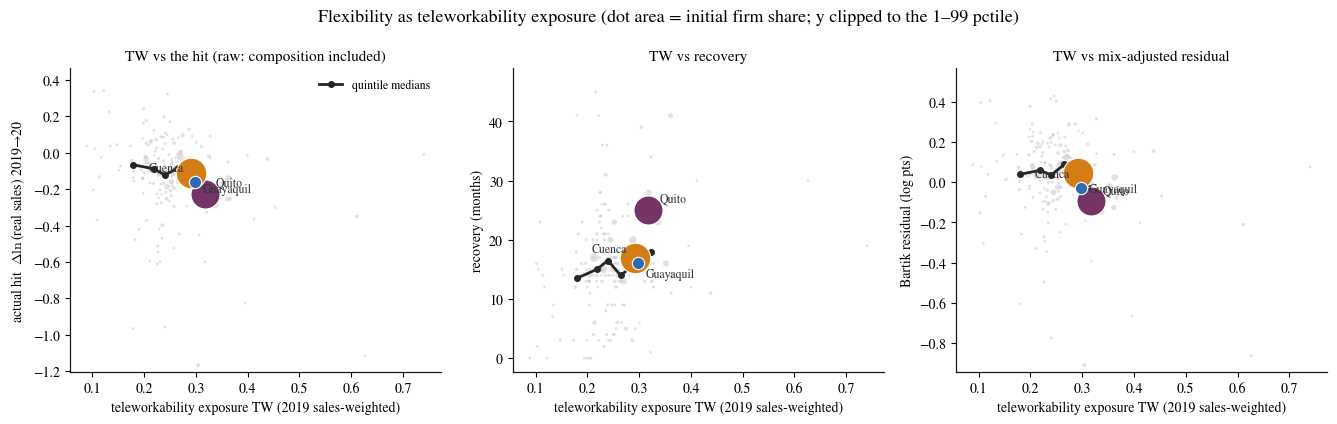


actual hit ~ teleworkability + size  (raw)
  n=174  R2=0.403  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept -0.0610    0.0906 -0.6740  0.5003 -0.2385  0.1165
tw        -0.3954    0.3325 -1.1891  0.2344 -1.0472  0.2563
log_firms  0.0118    0.0133  0.8854  0.3759 -0.0143  0.0379

actual hit ~ teleworkability beyond the Bartik  (the sharp test)
  n=174  R2=0.517  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  0.1908    0.0942  2.0251  0.0429  0.0061  0.3755
tw        -0.1547    0.2814 -0.5499  0.5824 -0.7062  0.3967
bartik     1.9265    0.3772  5.1068  0.0000  1.1871  2.6658
log_firms  0.0050    0.0114  0.4389  0.6608 -0.0174  0.0274

recovery months ~ teleworkability + composition + size
  n=168  R2=0.339  (province FE: yes; HC1 SEs)
             Coef.  Std.Err.       z   P>|z|   [0.025   0.975]
Intercept  -0.7726    4.2865 -0.1802  0.8570  -9.1740   7.6288
tw         30.4567   11.927

In [6]:
# ==============================================================================
# STEP E -- FRAMING 4: teleworkability exposure TW per unit
# ------------------------------------------------------------------------------
# tau_a = Dingel-Neiman (2020) teleworkable_emp by 2-digit NAICS, mapped to the
# ISIC rev-4 section (source NAICS noted per line; edit freely -- only the
# ordering/spread matters downstream). G blends wholesale (42, .52) and retail
# (44-45, .14) with ~27/73 US employment weights; E: waste sits in NAICS 56;
# T: domestic staff work on site; U treated like O. '9'/'V' (unclassified) are
# excluded and the weights renormalised over classified sections.
# ==============================================================================
TELEWORK = {
    "A": 0.076,   # 11     agriculture
    "B": 0.254,   # 21     mining
    "C": 0.225,   # 31-33  manufacturing
    "D": 0.370,   # 22     utilities
    "E": 0.311,   # 56     water/waste (remediation)
    "F": 0.186,   # 23     construction
    "G": 0.245,   # 42 + 44-45 blended
    "H": 0.186,   # 48-49  transport
    "I": 0.035,   # 72     accommodation & food
    "J": 0.717,   # 51     information
    "K": 0.762,   # 52     finance
    "L": 0.418,   # 53     real estate
    "M": 0.803,   # 54     professional/scientific
    "N": 0.311,   # 56     admin & support
    "O": 0.415,   # 99     public administration
    "P": 0.826,   # 61     education
    "Q": 0.253,   # 62     health
    "R": 0.297,   # 71     arts & recreation
    "S": 0.312,   # 81     other services
    "T": 0.000,   #        household employers: on site by definition
    "U": 0.415,   #        extraterritorial: like O
}
tau = pd.Series(TELEWORK)

def tw_exposure(comp):
    'mix-weighted teleworkability of a unit x section composition table'
    cls = [c for c in comp.columns if c in tau.index]
    w = comp[cls].div(comp[cls].sum(axis=1), axis=0)
    return (w * tau[cls]).sum(axis=1)

div["tw_sales"] = tw_exposure(sec19_sales)
div["tw_firms"] = tw_exposure(sec19_firms)

nat_tw = float((S19[[c for c in S19.index if c in tau.index]]
                / S19[[c for c in S19.index if c in tau.index]].sum() * tau).sum())
print(f"national sales-weighted TW = {nat_tw:.3f}   "
      f"(range across units: {div['tw_sales'].min():.3f}..{div['tw_sales'].max():.3f})")
print(f"corr(TW, Bartik) = {np.corrcoef(div['tw_sales'], bartik)[0, 1]:+.3f}   "
      "(overlap by construction; the conditional regression is the real test)")

print("\n--- the metros ---")
print(div.join(res["name"]).loc[list(METROS), ["name", "tw_sales", "tw_firms"]]
      .round(3).to_string())
print("\nmost teleworkable mixes:")
print(div.join(res["name"]).sort_values("tw_sales", ascending=False)
      [["name", "tw_sales"]].head(8).round(3).to_string())
print("\nleast teleworkable mixes:")
print(div.join(res["name"]).sort_values("tw_sales")
      [["name", "tw_sales"]].head(8).round(3).to_string())

# ---- figure: TW against the three outcomes -------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
panels = [(res["dln_sales"], "actual hit  $\\Delta\\ln$(real sales) 2019→20",
           "TW vs the hit (raw: composition included)"),
          (res["rec_sales"], "recovery (months)", "TW vs recovery"),
          (residual, "Bartik residual (log pts)", "TW vs mix-adjusted residual")]
for ax, (y, yl, ttl) in zip(axes, panels):
    x = div["tw_sales"]
    m_ = x.notna() & y.notna()
    ax.scatter(x[m_], y[m_], s=dot_area(res.loc[m_[m_].index, "p0"]),
               color=GRAY_DOT, alpha=0.55, lw=0)
    bx, by = binned_median(x[m_], y[m_])
    ax.plot(bx, by, color="0.15", lw=2.0, marker="o", ms=4, label="quintile medians")
    mark_metros(ax, x[m_], y[m_], res["p0"])
    lo, hi = np.nanpercentile(y[m_], [1, 99])
    pad = 0.05 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)            # display clip; table keeps all
    ax.set_xlabel("teleworkability exposure TW (2019 sales-weighted)", fontsize=10)
    ax.set_ylabel(yl, fontsize=10)
    ax.set_title(ttl, fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5, loc="best")
fig.suptitle("Flexibility as teleworkability exposure "
             "(dot area = initial firm share; y clipped to the 1–99 pctile)",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"teleworkability_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"teleworkability_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"teleworkability_{LEVEL}.png")
plt.show()

# ---- regressions: raw, then conditional on the Bartik ---------------------------
reg["tw"] = div["tw_sales"]
m4 = show_ols("actual ~ tw + log_firms" + fe,
              ["actual", "tw", "log_firms", "prov"],
              "actual hit ~ teleworkability + size  (raw)")
m5 = show_ols("actual ~ tw + bartik + log_firms" + fe,
              ["actual", "tw", "bartik", "log_firms", "prov"],
              "actual hit ~ teleworkability beyond the Bartik  (the sharp test)")
m6 = show_ols("recovery ~ tw + bartik + log_firms" + fe,
              ["recovery", "tw", "bartik", "log_firms", "prov"],
              "recovery months ~ teleworkability + composition + size")
print("\nreading the tw coefficient: TW moves ~0.1 between a rural and a metro "
      "mix, so multiply by 0.1 for an 'Ambato vs Quito' sized comparison.")

# ---- one file with everything: framings 1 + 2 + 3 + 4 ---------------------------
merged = res.join(div).join(pd.DataFrame({"bartik": bartik, "bartik_residual": residual}))
out = RES_DIR / f"resilience_metrics_{LEVEL}.csv"
merged.to_csv(out, encoding="utf-8-sig")
print(f"\nsaved -> {out}   ({merged.shape[0]} units x {merged.shape[1]} columns)")

## FRAMING 5 — reallocation flexibility: the Price decomposition *inside* each metro (STEP F)

The national decomposition treats parishes as the population; here the same pop-path machinery runs **inside** one unit, with its CIIU **sections** as the population: $p_a$ = the section's share of the unit's firm stock, fitness $w_a$ = the section's firm-stock growth, trait $z_a=\ln(\text{real sales})$ (the engine's convention). For one annual step,

$$\underbrace{\sum_a p_a\Big(\tfrac{w_a}{\bar W}-1\Big)z_a}_{\text{selection }S}\;+\;\underbrace{\sum_a p_a\tfrac{w_a}{\bar W}\,(z_a'-z_a)}_{\text{transmission }T}\;=\;\bar z'-\bar z\qquad\text{(identity, checked below)}$$

$S>0$ means the unit's **firm base is reallocating toward its higher-sales activities** — reorganization, the flexibility the teleworkability index failed to capture. $T$ is its incumbent sections' own sales change. Comparing Quito, Guayaquil, Cuenca and the pooled rest, year by year, asks directly: *when the shock hit, who reorganized?*

identity residual, worst: 8.7e-15

within-unit SELECTION across sections (log pts / yr):
group     Quito  Guayaquil  Cuenca  Rest of Ecuador
pair                                               
2017→18  0.0104     0.0052 -0.0031           0.0024
2018→19  0.0108    -0.0053 -0.0178          -0.0142
2019→20  0.0132     0.0096  0.0224           0.0275
2020→21  0.0364     0.0079  0.0241           0.0141
2021→22  0.0316     0.0096 -0.0157          -0.0010
2022→23  0.0315     0.0047 -0.0225          -0.0145

within-unit TRANSMISSION across sections (log pts / yr):
group     Quito  Guayaquil  Cuenca  Rest of Ecuador
pair                                               
2017→18  0.0088     0.0324  0.0961           0.0388
2018→19 -0.0352     0.0284  0.0021           0.0320
2019→20 -0.2531    -0.1770 -0.2348          -0.1923
2020→21  0.1549     0.1953  0.2350           0.2282
2021→22  0.0896     0.1105  0.1365           0.1221
2022→23  0.0490     0.0338  0.0629           0.0647



saved -> results/resilience/within_metro_price_parish.png


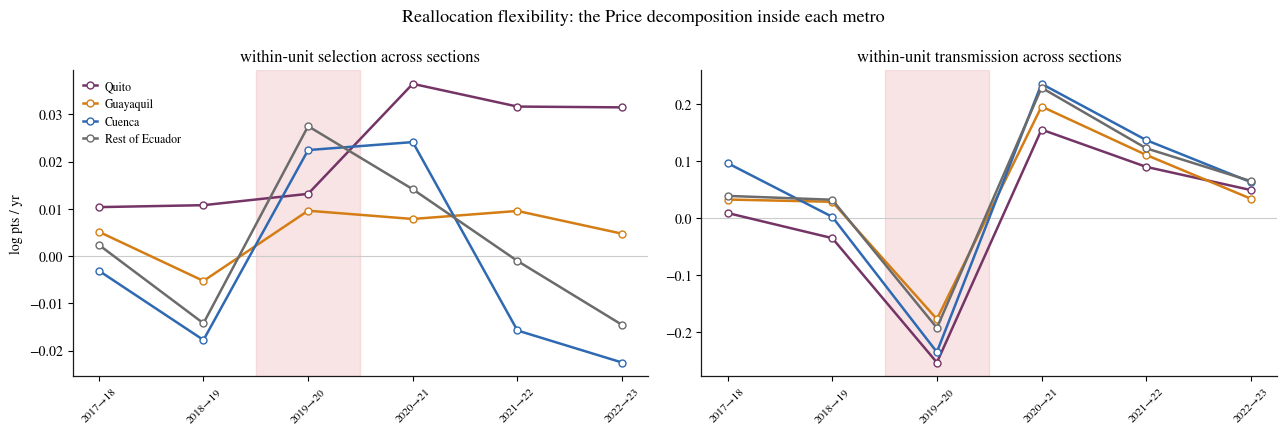

In [7]:
# ==============================================================================
# STEP F -- FRAMING 5: within-unit Price decomposition across CIIU sections
# ------------------------------------------------------------------------------
# Same conventions as the engine: population = section firm stock (mean of the
# year's monthly stocks), trait = ln(section real sales), survivors only
# (sections alive at both ends). S + T = zbar' - zbar to machine precision.
# ==============================================================================
GROUPS = {lab: [u] for u, lab in METROS.items()}
GROUPS["Rest of Ecuador"] = [u for u in KEEP if u not in METROS]
GROUP_C = dict(METRO_C, **{"Rest of Ecuador": CUSTOM_GRAY})

def section_panel(unit_codes):
    'per CIIU section: annual mean firm stock and real sales, pooled over units'
    d = df[df["unit"].isin(unit_codes) & df["year"].isin(FULL_YEARS)]
    firms = (d.groupby(["cod_ciuu4", "year"])["total_firms"].sum()
              .unstack("year").fillna(0.0) / 12.0)
    sales = (d.groupby(["cod_ciuu4", "year"])["real_sales"].sum()
              .unstack("year").fillna(0.0))
    return firms, sales

def price_terms(firms, sales, y0, y1):
    'pop-path selection / transmission / total across sections, one annual step'
    ok = (firms[y0] > 0) & (firms[y1] > 0) & (sales[y0] > 0) & (sales[y1] > 0)
    n0, n1 = firms.loc[ok, y0], firms.loc[ok, y1]
    z0, z1 = np.log(sales.loc[ok, y0]), np.log(sales.loc[ok, y1])
    p, w = n0 / n0.sum(), n1 / n0
    W = (p * w).sum()
    sel   = (p * (w / W - 1) * z0).sum()
    trans = (p * (w / W) * (z1 - z0)).sum()
    total = (p * w / W * z1).sum() - (p * z0).sum()
    return sel, trans, total

rows = []
for lab, codes in GROUPS.items():
    firms, sales = section_panel(codes)
    for y0, y1 in zip(FULL_YEARS[:-1], FULL_YEARS[1:]):
        sel, trans, total = price_terms(firms, sales, y0, y1)
        rows.append(dict(group=lab, pair=f"{y0}→{y1 % 100:02d}",
                         selection=sel, transmission=trans, total=total,
                         residual=total - (sel + trans)))
pt = pd.DataFrame(rows)
assert pt["residual"].abs().max() < 1e-9, "Price identity violated"
print(f"identity residual, worst: {pt['residual'].abs().max():.1e}\n")
print("within-unit SELECTION across sections (log pts / yr):")
print(pt.pivot(index="pair", columns="group", values="selection")
      [list(GROUPS)].round(4).to_string())
print("\nwithin-unit TRANSMISSION across sections (log pts / yr):")
print(pt.pivot(index="pair", columns="group", values="transmission")
      [list(GROUPS)].round(4).to_string())

xt = sorted(pt["pair"].unique())
covid_i = xt.index("2019→20")
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4), sharex=True)
for ax, term in zip(axes, ["selection", "transmission"]):
    ax.axvspan(covid_i - 0.5, covid_i + 0.5, color=RED_DOT, alpha=0.30, zorder=0)
    ax.axhline(0, color="0.8", lw=0.8)
    for lab in GROUPS:
        v = pt[pt["group"] == lab].set_index("pair").loc[xt, term]
        ax.plot(range(len(xt)), v.values, lw=1.8, marker="o", ms=5,
                color=GROUP_C[lab], mfc="white", mec=GROUP_C[lab], label=lab)
    ax.set_xticks(range(len(xt)))
    ax.set_xticklabels(xt, rotation=45, fontsize=8)
    ax.set_title(f"within-unit {term} across sections", fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("log pts / yr", fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, loc="best",
               handlelength=1.2, handletextpad=0.6)
fig.suptitle("Reallocation flexibility: the Price decomposition inside each metro",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"within_metro_price_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"within_metro_price_{LEVEL}.pdf", bbox_inches="tight")
print("\nsaved ->", RES_DIR / f"within_metro_price_{LEVEL}.png")
plt.show()

## FRAMING 6 — the portfolio test: did diversity lower pre-COVID volatility at all? (STEP G)

The diversification-as-insurance argument has a testable premise that comes *before* any shock: a diversified portfolio should have a **less volatile aggregate** — unless its components all move together. Per unit, volatility = the standard deviation of monthly **year-over-year** log real-sales growth over the pre-shock window (YoY differencing kills seasonality without smoothing anything). Two questions: (a) does $N^{\text{eff}}$ predict *lower* pre-COVID volatility (the portfolio channel exists), raw and size-partialled — small units are mechanically noisier, so only the partialled number counts; (b) does pre-shock volatility predict the COVID hit — was "calm before" worth anything when a *correlated* shock arrived?

pre-COVID volatility (sd of monthly YoY log growth, 2018-01..2020-02):  median 0.197
                                                                                                             name  vol_pre  neff_sales
unit                                                                                                                                  
170150  Quito Distrito Metropolitano, Cabecera Cantonal, Capital Provincial Y De La Republica Del Ecuador (Quito)    0.046       8.155
090150                                                                                      Guayaquil (Guayaquil)    0.034       6.700
010150                                                                                            Cuenca (Cuenca)    0.078       5.281

(a) the portfolio premise -- diversity vs pre-COVID volatility:
    spearman -0.141   pearson -0.161   size-partialled +0.054
(b) did calm-before predict the hit?
    vol_pre vs actual hit 2019→20    : spearman -0.083   size-partialled -0.

saved -> results/resilience/portfolio_volatility_parish.png


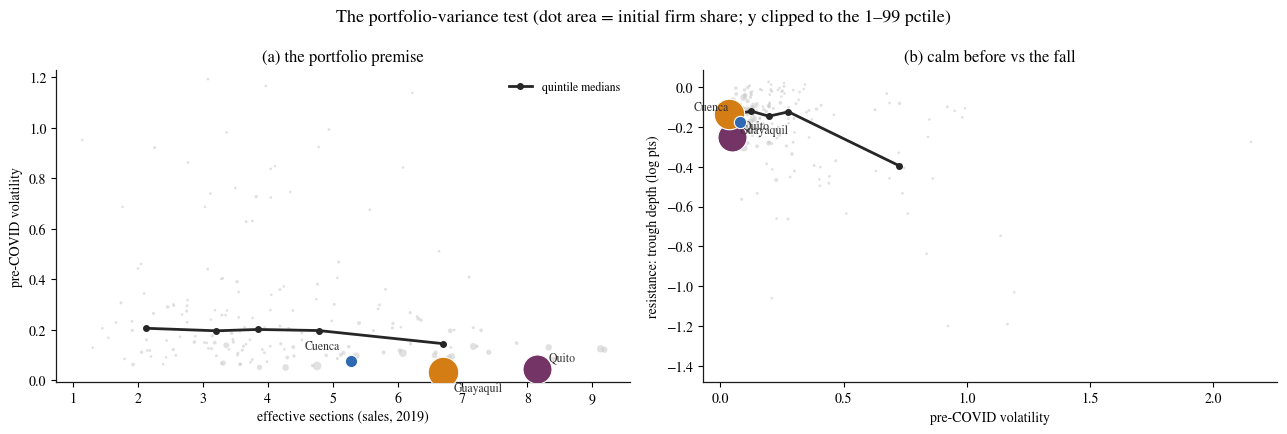

In [8]:
# ==============================================================================
# STEP G -- FRAMING 6: pre-COVID volatility vs diversity, and vs the hit
# ==============================================================================
VOL_FROM = pd.Period("2018-01", "M")            # YoY needs 2017 as its base year
yoy = np.log(SALES_M[KEEP] / SALES_M[KEEP].shift(12)).replace(
    [np.inf, -np.inf], np.nan)
vol = yoy.loc[VOL_FROM:BENCH_P].std()
div["vol_pre"] = vol

print("pre-COVID volatility (sd of monthly YoY log growth, "
      f"{VOL_FROM}..{BENCH_P}):  median {vol.median():.3f}")
print(div.join(res["name"]).loc[list(METROS), ["name", "vol_pre", "neff_sales"]]
      .round(3).to_string())
print("\n(a) the portfolio premise -- diversity vs pre-COVID volatility:")
m_ = vol.notna()
print(f"    spearman {sps.spearmanr(div['neff_sales'][m_], vol[m_]).statistic:+.3f}   "
      f"pearson {sps.pearsonr(div['neff_sales'][m_], vol[m_]).statistic:+.3f}   "
      f"size-partialled {partial_r(div['neff_sales'], vol, log_firms0):+.3f}")
print("(b) did calm-before predict the hit?")
for out_, lab_ in [("dln_sales", "actual hit 2019→20"),
                   ("res_sales", "trough depth"), ("rec_sales", "recovery months")]:
    y = res[out_]
    mm = vol.notna() & y.notna()
    print(f"    vol_pre vs {lab_:22s}: "
          f"spearman {sps.spearmanr(vol[mm], y[mm]).statistic:+.3f}   "
          f"size-partialled {partial_r(vol, y, log_firms0):+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4))
panels = [(div["neff_sales"], vol, "effective sections (sales, 2019)",
           "pre-COVID volatility", "(a) the portfolio premise"),
          (vol, res["res_sales"], "pre-COVID volatility",
           "resistance: trough depth (log pts)", "(b) calm before vs the fall")]
for ax, (x, y, xl, yl, ttl) in zip(axes, panels):
    m_ = x.notna() & y.notna()
    ax.scatter(x[m_], y[m_], s=dot_area(res.loc[m_[m_].index, "p0"]),
               color=GRAY_DOT, alpha=0.55, lw=0)
    bx, by = binned_median(x[m_], y[m_])
    ax.plot(bx, by, color="0.15", lw=2.0, marker="o", ms=4, label="quintile medians")
    mark_metros(ax, x[m_], y[m_], res["p0"])
    lo, hi = np.nanpercentile(y[m_], [1, 99])
    pad = 0.05 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)             # display clip; table keeps all
    ax.set_xlabel(xl, fontsize=10); ax.set_ylabel(yl, fontsize=10)
    ax.set_title(ttl, fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5, loc="best")
fig.suptitle("The portfolio-variance test "
             "(dot area = initial firm share; y clipped to the 1–99 pctile)",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"portfolio_volatility_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"portfolio_volatility_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"portfolio_volatility_{LEVEL}.png")
plt.show()

## How each economic activity took the hit — and what each parish's sales are made of (STEP H)

Two descriptive views that anchor everything above. First, the **activities themselves**: each CIIU section's national trailing-12m real sales run through the *same* trough/recovery machinery as the parishes — one resistance-and-recovery line per activity, plus indexed trajectories for the biggest sections. Second, the **composition bars**: what the biggest parishes' 2019 sales are made of, with sections stacked hardest-hit → best-held, so the left end of every bar is its exposed flank. The one-number version, `hardhit_share` — the share of a parish's 2019 sales in sections that fell *more than the national average* — joins the metrics CSV as the simplest composition-based resilience measure (it is the Bartik's blunt cousin: pure exposure, no growth-rate weighting).

per-activity resistance and recovery (0 trough = never fell; NaN months = not back by 2024-10):
                          activity  share19  dln_19_20  trough trough_month  months_back
cod_ciuu4                                                                               
V                     Unclassified    0.000     -1.912  -3.956      2021-04          NaN
9                     Unclassified    0.000     -0.401  -0.934      2021-02          NaN
T              Household employers    0.000      0.637  -0.596      2020-11          9.0
I             Accommodation & food    0.014     -0.469  -0.570      2021-02         31.0
R                Arts & recreation    0.002     -0.436  -0.565      2021-03         33.0
N                  Admin. services    0.023     -0.312  -0.382      2021-02         30.0
F                     Construction    0.032     -0.375  -0.381      2021-02         33.0
B                           Mining    0.038     -0.277  -0.360      2021-02         32.0
O            P

saved -> results/resilience/sector_trajectories.png


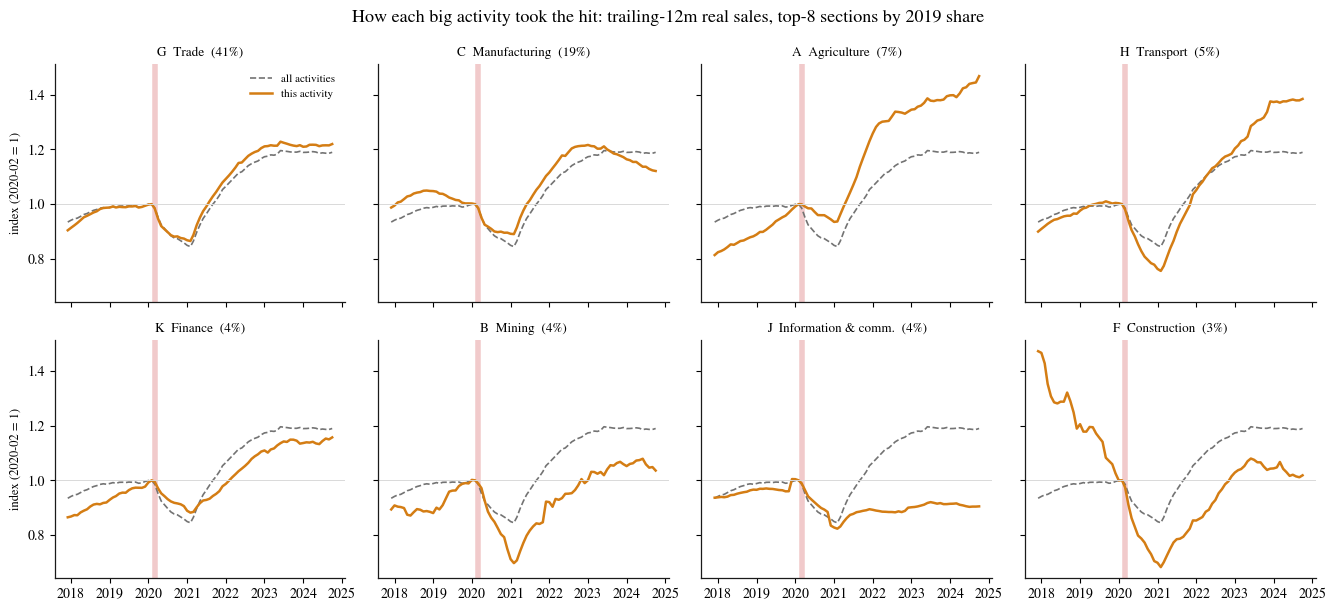

In [9]:
# ==============================================================================
# STEP H -- the activities themselves: resistance and recovery per CIIU section
# ------------------------------------------------------------------------------
# National (kept units) trailing-12m real sales per section, through the same
# trough_and_recovery as the parishes. Table sorted hardest-hit first; small
# multiples for the top-8 sections by 2019 share, each vs the all-section total.
# ==============================================================================
SEC_M = (df[df["unit"].isin(KEEP)]
         .groupby(["cod_ciuu4", "ym"])["real_sales"].sum()
         .unstack("cod_ciuu4").reindex(months).fillna(0.0))
S12sec = SEC_M.rolling(12, min_periods=12).sum()
res_sec, tr_sec, rec_sec = trough_and_recovery(S12sec, S12sec.loc[BENCH_P])

sec_tab = pd.DataFrame({
    "activity":     [SEC_NAME.get(a, a) for a in S12sec.columns],
    "share19":      share19.reindex(S12sec.columns).round(3),
    "dln_19_20":    g_all.reindex(S12sec.columns).round(3),
    "trough":       res_sec.round(3),
    "trough_month": tr_sec.astype(str),
    "months_back":  rec_sec,
}, index=S12sec.columns).sort_values("trough")
print("per-activity resistance and recovery (0 trough = never fell; "
      f"NaN months = not back by {LAST_P}):")
print(sec_tab.to_string())
sec_tab.to_csv(RES_DIR / "sector_hit_recovery.csv", encoding="utf-8-sig")

top8 = share19.sort_values(ascending=False).index[:8]
tot = S12sec.dropna().sum(axis=1)      # drop the empty first 11 window months
fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.2), sharex=True, sharey=True)
for ax, a in zip(axes.ravel(), top8):
    s = (S12sec[a] / S12sec.loc[BENCH_P, a]).dropna()
    t = (tot / tot.loc[BENCH_P]).dropna()
    ax.plot(t.index.to_timestamp(), t.values, color="0.45", lw=1.2, ls="--",
            label="all activities")
    ax.plot(s.index.to_timestamp(), s.values, color=CUSTOM_ORANGE, lw=1.8,
            label="this activity")
    ax.axhline(1, color="0.85", lw=0.7)
    ax.axvline(SHOCK_P.to_timestamp(), color=RED_DOT, lw=4, alpha=0.6, zorder=0)
    ax.set_title(f"{a}  {SEC_NAME.get(a, a)}  ({100 * share19[a]:.0f}%)",
                 fontsize=9.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8)
axes[0, 0].set_ylabel(f"index ({BENCH_P} = 1)", fontsize=9)
axes[1, 0].set_ylabel(f"index ({BENCH_P} = 1)", fontsize=9)
fig.suptitle("How each big activity took the hit: trailing-12m real sales, "
             "top-8 sections by 2019 share", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / "sector_trajectories.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / "sector_trajectories.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / "sector_trajectories.png")
plt.show()

national hit -0.148; 'hard-hit' = fell more than that: 9, B, F, H, I, J, L, M, N, O, P, R, S, U, V

--- the metros: composition top-5 and hard-hit exposure ---
  Quito      hardhit 34%   G Trade 40%, C Manufacturing 15%, B Mining 10%, K Finance 7%, M Professional/scientific 5%
  Guayaquil  hardhit 22%   G Trade 47%, C Manufacturing 16%, A Agriculture 8%, J Information & comm. 6%, H Transport 5%
  Cuenca     hardhit 16%   G Trade 47%, C Manufacturing 28%, P Education 5%, Q Health 3%, D Electricity/gas 3%

hardhit_share vs the outcomes:
  vs actual hit      : spearman -0.398   size-partialled -0.476
  vs trough depth    : spearman -0.484   size-partialled -0.528
  vs recovery months : spearman +0.176   size-partialled +0.290


saved -> results/resilience/composition_parish.png


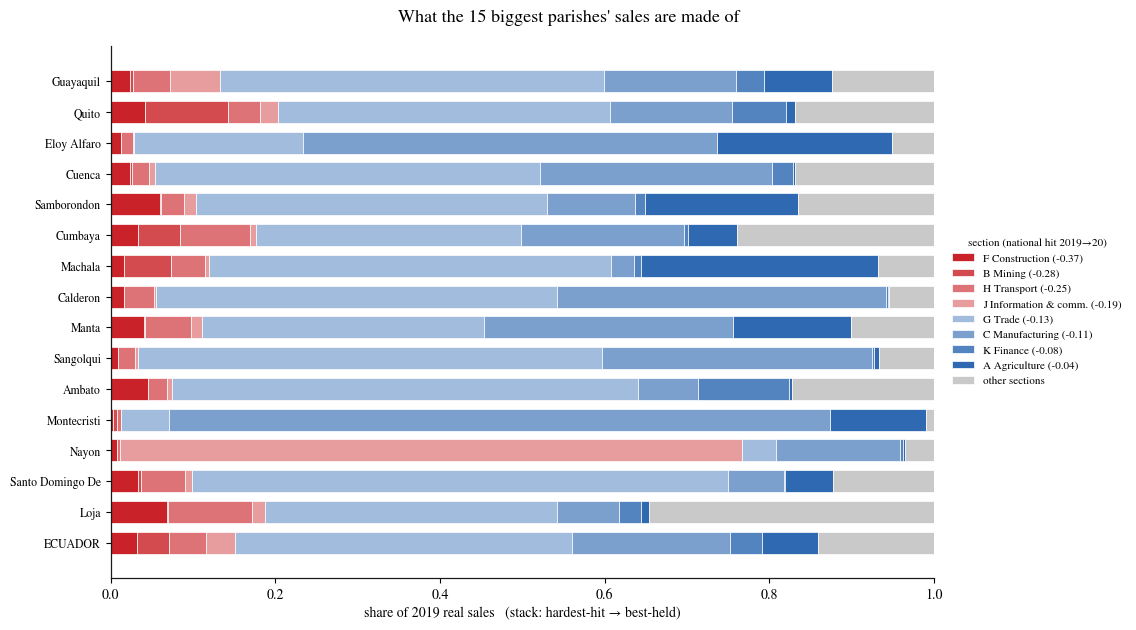

saved -> results/resilience/resilience_metrics_parish.csv   (174 units x 25 columns)


In [10]:
# ==============================================================================
# STEP H (cont.) -- parish composition: stacked 2019 sales shares + hardhit_share
# ------------------------------------------------------------------------------
# Sections stacked hardest-hit (left) -> best-held; top-8 sections by national
# share get fixed colours, everything else folds into "other". hardhit_share =
# share of 2019 sales in sections that fell more than the national average.
# The merged metrics CSV (framings 1-6 + composition) is re-saved at the end.
# ==============================================================================
w_s = sec19_sales.div(sec19_sales.sum(axis=1), axis=0)      # 2019 sales shares
g_total = float(np.log(S20.sum() / S19.sum()))
hard = [a for a in g_all.index if pd.notna(g_all[a]) and g_all[a] < g_total]
div["hardhit_share"] = w_s[[c for c in hard if c in w_s.columns]].sum(axis=1)

print(f"national hit {g_total:+.3f}; 'hard-hit' = fell more than that: "
      + ", ".join(sorted(hard)))
print("\n--- the metros: composition top-5 and hard-hit exposure ---")
for u, lab in METROS.items():
    t5 = w_s.loc[u].sort_values(ascending=False).head(5)
    mix = ", ".join(f"{a} {SEC_NAME.get(a, a)} {100 * v:.0f}%"
                    for a, v in t5.items())
    print(f"  {lab:10s} hardhit {100 * div.loc[u, 'hardhit_share']:.0f}%   {mix}")
print("\nhardhit_share vs the outcomes:")
for out_, lab_ in [("dln_sales", "actual hit"), ("res_sales", "trough depth"),
                   ("rec_sales", "recovery months")]:
    y = res[out_]
    mm = y.notna()
    print(f"  vs {lab_:16s}: "
          f"spearman {sps.spearmanr(div['hardhit_share'][mm], y[mm]).statistic:+.3f}   "
          f"size-partialled {partial_r(div['hardhit_share'], y, log_firms0):+.3f}")

# ---- stacked composition bars: biggest units + Ecuador --------------------------
TOPN = 15
big = list(res["sales0"].sort_values(ascending=False).index[:TOPN])
stack = [a for a in g_all.sort_values().index if a in top8]  # hardest-hit first
# colours follow the stack: red for the half that was hit hardest (darkest =
# hardest), blue for the half that held (darkest = held best)
SEC_C = dict(zip(stack, style.ramp(style.RED, 4)[::-1] + style.ramp(style.BLUE, 4)))
SEC_C["other"] = style.CONTEXT

comp = w_s.loc[big, stack].copy()
comp.loc["EC"] = share19.reindex(stack).values                # national reference
comp["other"] = 1.0 - comp.sum(axis=1)

def short_name(u):
    return "ECUADOR" if u == "EC" else METROS.get(u, uname(u).split(" (")[0][:16])

fig, ax = plt.subplots(figsize=(11.5, 6.4))
order = comp.index[::-1]                                      # biggest on top
left = np.zeros(len(comp))
for a in stack + ["other"]:
    lab = (f"{a} {SEC_NAME.get(a, a)} ({g_all[a]:+.2f})" if a != "other"
           else "other sections")
    ax.barh([short_name(u) for u in order], comp.loc[order, a].values,
            left=left, color=SEC_C[a], height=0.72, edgecolor="white", lw=0.5,
            label=lab)
    left += comp.loc[order, a].values
ax.set_xlim(0, 1)
ax.set_xlabel("share of 2019 real sales   (stack: hardest-hit → best-held)",
              fontsize=10)
ax.tick_params(axis="y", labelsize=8.5)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5),
          title=f"section (national hit {SHOCK_Y0}→{SHOCK_Y1 % 100:02d})",
          title_fontsize=8)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.suptitle(f"What the {TOPN} biggest parishes' sales are made of", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"composition_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"composition_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"composition_{LEVEL}.png")
plt.show()

# ---- one file with everything: framings 1-6 + composition -----------------------
merged = res.join(div).join(pd.DataFrame({"bartik": bartik, "bartik_residual": residual}))
out = RES_DIR / f"resilience_metrics_{LEVEL}.csv"
merged.to_csv(out, encoding="utf-8-sig")
print(f"saved -> {out}   ({merged.shape[0]} units x {merged.shape[1]} columns)")

## STEP I — the same questions on the firm-count margin

Sales are dominated by the big established firms, so every sales-weighted view over-represents them. The firm stock is the democratic margin: one firm, one vote. Re-asked here: **which activities gained or lost firms** (shock year and through the recovery), side by side with their sales growth — the gap between the two margins is itself informative (an activity can lose a third of its sales while its firm base keeps growing, and vice versa) — and **how the least vs most firm-diversified parishes did**, using firm-share entropy ($N^{\text{eff}}$ of firms) and firm-margin outcomes.

per-activity FIRM-stock growth, with its sales growth alongside:
                          activity  firm_share19  sales_share19  dln_firms_19_20  dln_firms_19_23  dln_sales_19_20
cod_ciuu4                                                                                                         
D                  Electricity/gas         0.002          0.008            0.174            0.867           -0.036
J              Information & comm.         0.029          0.036            0.122            0.548           -0.185
I             Accommodation & food         0.018          0.014            0.097            0.545           -0.469
Q                           Health         0.039          0.020            0.094            0.540           -0.013
P                        Education         0.023          0.015            0.091            0.489           -0.182
F                     Construction         0.074          0.032            0.111            0.462           -0.375
R              

saved -> results/resilience/sector_firm_growth.png


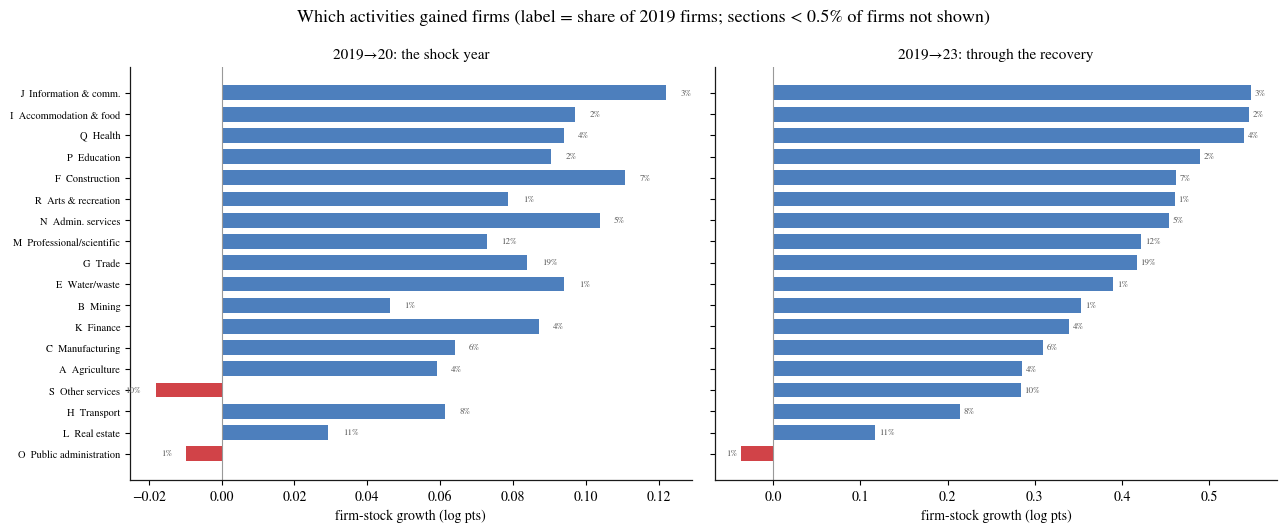


outcomes by FIRM-diversity quintile (medians):
             n  neff_firms   firms0  trough_firms  months_back_firms  dln_firms  trough_sales
neff_firms                                                                                   
Q1 least    35       4.855   69.167        -0.004                4.0      0.028        -0.162
Q2          35       6.547   81.917         0.000                0.0      0.038        -0.130
Q3          34       7.869  135.000        -0.003                4.0      0.045        -0.120
Q4          35       9.166  180.000         0.002                0.0      0.048        -0.115
Q5 most     35      11.226  870.083         0.007                0.0      0.064        -0.163


In [11]:
# ==============================================================================
# STEP I -- activities and diversity, on the FIRM-COUNT margin
# ------------------------------------------------------------------------------
# Firm stock per section-year = the year's summed monthly stocks / 12 (kept
# units). Growth over the shock year and 2019->2023; sales growth alongside
# for the margin gap. Quintile table: firm-share diversity vs firm outcomes.
# ==============================================================================
fsec_y = (df[df["unit"].isin(KEEP) & df["year"].isin(FULL_YEARS)]
          .groupby(["cod_ciuu4", "year"])["total_firms"].sum()
          .unstack("year").fillna(0.0) / 12.0)
fshare19 = fsec_y[T0_YEAR] / fsec_y[T0_YEAR].sum()
gF_1920 = np.log(fsec_y[SHOCK_Y1].where(fsec_y[SHOCK_Y1] > 0)
                 / fsec_y[SHOCK_Y0].where(fsec_y[SHOCK_Y0] > 0))
gF_1923 = np.log(fsec_y[2023].where(fsec_y[2023] > 0)
                 / fsec_y[SHOCK_Y0].where(fsec_y[SHOCK_Y0] > 0))

firm_tab = pd.DataFrame({
    "activity":        [SEC_NAME.get(a, a) for a in fsec_y.index],
    "firm_share19":    fshare19.round(3),
    "sales_share19":   share19.reindex(fsec_y.index).round(3),
    "dln_firms_19_20": gF_1920.round(3),
    "dln_firms_19_23": gF_1923.round(3),
    "dln_sales_19_20": g_all.reindex(fsec_y.index).round(3),
}, index=fsec_y.index).sort_values("dln_firms_19_23", ascending=False)
print("per-activity FIRM-stock growth, with its sales growth alongside:")
print(firm_tab[firm_tab["firm_share19"] >= 0.002].to_string())
firm_tab.to_csv(RES_DIR / "sector_firm_growth.csv", encoding="utf-8-sig")

show_secs = [a for a in fsec_y.index if fshare19[a] >= 0.005]
order = gF_1923[show_secs].sort_values().index          # one order, both panels
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4), sharey=True)
for ax, (v, ttl) in zip(axes, [
        (gF_1920, f"{SHOCK_Y0}→{SHOCK_Y1 % 100:02d}: the shock year"),
        (gF_1923, f"{SHOCK_Y0}→23: through the recovery")]):
    vals = v[order]
    cols_ = [CUSTOM_RED if x < 0 else CUSTOM_BLUE for x in vals]
    ax.barh([f"{a}  {SEC_NAME.get(a, a)}" for a in order], vals.values,
            color=cols_, alpha=0.85, height=0.7)
    for k, a in enumerate(order):
        ax.text(vals[a] + (0.004 if vals[a] >= 0 else -0.004), k,
                f"{100 * fshare19[a]:.0f}%", va="center",
                ha="left" if vals[a] >= 0 else "right", fontsize=6.5, color="0.35")
    ax.axvline(0, color="0.6", lw=0.8)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_xlabel("firm-stock growth (log pts)", fontsize=10)
    ax.set_title(ttl, fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.suptitle("Which activities gained firms (label = share of 2019 firms; "
             "sections < 0.5% of firms not shown)", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / "sector_firm_growth.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / "sector_firm_growth.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / "sector_firm_growth.png")
plt.show()

# ---- diversity quintiles, firm margin -------------------------------------------
qf = pd.qcut(div["neff_firms"], 5,
             labels=["Q1 least", "Q2", "Q3", "Q4", "Q5 most"])
tabq = (res.join(div).groupby(qf, observed=True)
        .agg(n=("neff_firms", "size"), neff_firms=("neff_firms", "median"),
             firms0=("firms0", "median"),
             trough_firms=("res_firms", "median"),
             months_back_firms=("rec_firms", "median"),
             dln_firms=("dln_firms", "median"),
             trough_sales=("res_sales", "median")))
print("\noutcomes by FIRM-diversity quintile (medians):")
print(tabq.round(3).to_string())

## STEP J — the three metros side by side: how each lived the shock

Two views. **Timing**: monthly year-over-year real-sales growth (raw months — YoY differencing kills seasonality without the 12-month smoothing, so the crater's true depth and duration show). **Anatomy**: each metro's 2019→20 change decomposed *exactly* into section contributions on both margins,

$$\frac{\Delta X}{X_{19}}=\sum_a w_{a,19}\Big(\frac{x_{a,20}}{x_{a,19}}-1\Big),$$

so the bars answer "which activities produced *this* metro's shock" — same sections, same scale, three cities. Sales tell who lost the money; firms tell whose business fabric actually tore.

saved -> results/resilience/metro_monthly_yoy.png


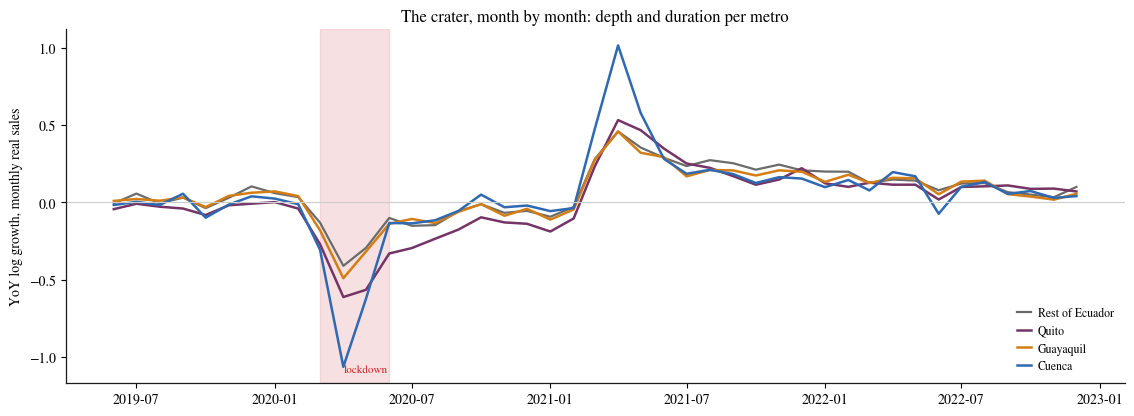


SALES: total 2019→20 % change and top-3 section drags per metro
  Quito      total  -20.3%   G -7.8pp  B -2.6pp  C -2.6pp


  Guayaquil  total  -10.6%   G -3.9pp  C -1.6pp  J -1.0pp
  Cuenca     total  -15.1%   G -7.6pp  C -3.7pp  F -0.7pp

FIRMS: total 2019→20 % change and top-3 section drags per metro
  Quito      total   +7.7%   9 -0.0pp  T +0.0pp  U +0.0pp
  Guayaquil  total   +6.4%   U -0.0pp  T -0.0pp  O +0.0pp
  Cuenca     total   +8.4%   S -0.6pp  V -0.0pp  O +0.0pp



saved -> results/resilience/metro_anatomy.png


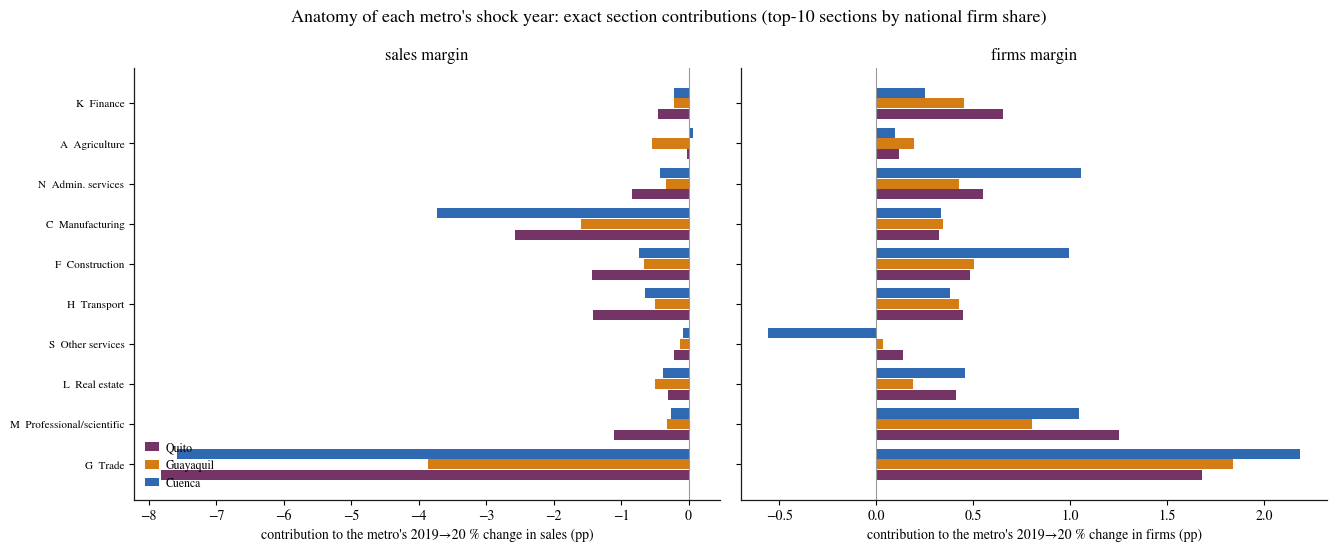

In [12]:
# ==============================================================================
# STEP J -- metro anatomy: timing (monthly YoY) + exact section contributions
# ==============================================================================
# ---- (1) timing: monthly YoY real-sales growth ----------------------------------
with np.errstate(divide="ignore"):
    yoym = np.log(SALES_M / SALES_M.shift(12)).replace([np.inf, -np.inf], np.nan)
rest = [u for u in KEEP if u not in METROS]
rest_tot = SALES_M[rest].sum(axis=1)
with np.errstate(divide="ignore"):
    rest_yoy = np.log(rest_tot / rest_tot.shift(12)).replace(
        [np.inf, -np.inf], np.nan)
win = pd.period_range("2019-06", "2022-12", freq="M")
x = win.to_timestamp()

fig, ax = plt.subplots(figsize=(11.5, 4.3))
ax.plot(x, rest_yoy.loc[win].values, color=CUSTOM_GRAY, lw=1.6,
        label="Rest of Ecuador")
for u, lab in METROS.items():
    ax.plot(x, yoym.loc[win, u].values, color=METRO_C[lab], lw=1.8, label=lab)
ax.axhline(0, color="0.8", lw=0.8)
ax.axvspan(pd.Period("2020-03", "M").to_timestamp(),
           pd.Period("2020-06", "M").to_timestamp(),
           color=RED_DOT, alpha=0.35, zorder=0)
ax.annotate("lockdown", xy=(pd.Period("2020-04", "M").to_timestamp(), 0.03),
            xycoords=("data", "axes fraction"), fontsize=8, color=CUSTOM_RED)
ax.set_ylabel("YoY log growth, monthly real sales", fontsize=10)
ax.set_title("The crater, month by month: depth and duration per metro", fontsize=12)
ax.legend(frameon=False, fontsize=8.5, loc="lower right",
          handlelength=1.2, handletextpad=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(RES_DIR / "metro_monthly_yoy.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / "metro_monthly_yoy.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / "metro_monthly_yoy.png")
plt.show()

# ---- (2) anatomy: exact section contributions to the 2019->20 change ------------
def metro_contrib(u, margin):
    'per section: w19 * (x20/x19 - 1); sums to the metro pct change on that margin'
    d_ = df[(df["unit"] == u) & df["year"].isin([SHOCK_Y0, SHOCK_Y1])]
    if margin == "sales":
        t = d_.groupby(["cod_ciuu4", "year"])["real_sales"].sum().unstack("year")
    else:
        t = d_.groupby(["cod_ciuu4", "year"])["total_firms"].sum().unstack("year") / 12.0
    t = t.fillna(0.0)
    ok = t[SHOCK_Y0] > 0
    w = t.loc[ok, SHOCK_Y0] / t.loc[ok, SHOCK_Y0].sum()
    return w * (t.loc[ok, SHOCK_Y1] / t.loc[ok, SHOCK_Y0] - 1)

secs_j = list(fshare19.sort_values(ascending=False).index[:10])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), sharey=True)
for ax, margin in zip(axes, ["sales", "firms"]):
    print(f"\n{margin.upper()}: total 2019→20 % change and top-3 section drags per metro")
    y = np.arange(len(secs_j))
    for k, (u, lab) in enumerate(METROS.items()):
        c = metro_contrib(u, margin)
        ax.barh(y + (k - 1) * 0.27, 100 * c.reindex(secs_j).fillna(0.0).values,
                height=0.25, color=METRO_C[lab], label=lab)
        drags = c.sort_values().head(3)
        print(f"  {lab:10s} total {100 * c.sum():+6.1f}%   "
              + "  ".join(f"{a} {100 * v:+.1f}pp" for a, v in drags.items()))
    ax.set_yticks(y)
    ax.set_yticklabels([f"{a}  {SEC_NAME.get(a, a)}" for a in secs_j], fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_xlabel(f"contribution to the metro's {SHOCK_Y0}→{SHOCK_Y1 % 100:02d} "
                  f"% change in {margin} (pp)", fontsize=10)
    ax.set_title(f"{margin} margin", fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5, loc="lower left",
               handlelength=1.2, handletextpad=0.6)
fig.suptitle("Anatomy of each metro's shock year: exact section contributions "
             "(top-10 sections by national firm share)", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / "metro_anatomy.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / "metro_anatomy.pdf", bbox_inches="tight")
print("\nsaved ->", RES_DIR / "metro_anatomy.png")
plt.show()

## FRAMING 7 — the fine grain: mega-firm cells and the "regular economy" (STEPS K & L)

Everything so far treated a parish's sales as one number per CIIU **section** — but Quito's sales are not "Quito's economy" in any democratic sense: a handful of cells (crude oil `B061`, oil-services `B091`, vehicle importers `G451`, fuel wholesalers) contain one or a few giant firms whose revenues dwarf the thousands of small firms around them. If those cells drove the 2020 crater, then "Quito fell hardest" is a story about a few balance sheets, not about the city's economic fabric — and every diversity correlation upstream is contaminated by them.

**The data that makes this testable.** `data/processed/df_ciuu_dpa.csv` is the sales extract at CIIU rev-4 **group** level (`ciiun4`: 239 codes like `B061`, `G466`), parish × month × group × taxpayer type. It is used here exactly as the decomposition uses the sales data: **private companies only** (`SDD_NO_PUB`) and sales = `V_VTX`, total sales including exports. Two facts about it matter:

1. It has **no firm count at this level of detail**. The extract documents only a *range* of taxpayers per cell (`num_rango_desde`, `num_rango_hasta`); its `count_id` column is not documented by the SRI and is not used. So activity mix is measured on **sales shares**, and the only thing taken from the range is its top, as an upper bound.
2. Its section-level totals reproduce the STEP-A sales of the analysis table almost exactly; the validation cell prints the comparison.

**The mega-firm rule (STEP L).** A cell (parish × group) is *mega-firm dominated* if its baseline sales per taxpayer — sales divided by the **top** of the cell's documented taxpayer range, so a guaranteed minimum — exceeds the `MEGA_PCT` (default P99) quantile of all baseline cells — a data-driven rule that catches the oil complex *and* the non-oil giants (vehicle importers, airlines, telecoms) that a named "drop oil" rule would miss; oil (`B061 B062 B091 C192`) is still reported separately as the named special case. The **regular economy** of a parish is everything outside its flagged cells. The whole trough/recovery machinery of STEP B then re-runs on regular-economy sales — the test being: *does Quito's (and everyone's) resilience ranking, and the diversification null, survive once the mega-firms are removed?*

In [13]:
# ==============================================================================
# STEP K -- the fine-grained panel: unit x month x CIIU group, real sales
# ------------------------------------------------------------------------------
# Reads the CIIU-4 sales table with the SAME population and sales variable as
# STEP A and the decomposition: private companies, sales = V_VTX. Deflates with
# the same IPC factors, restricts to the same window and KEEP units. There is
# no firm count at this level of detail: max_taxpayers is the documented TOP of
# the taxpayer range of the cell (an upper bound), used only by the mega flag.
# GRP_NAME comes from the CIIU 4.0 rows of dic_ciiu.xlsx. Validation at the
# end: section-level sales, fine vs the STEP-A table, 2019, kept units.
# ==============================================================================
fine = pd.read_csv(paths.SALES_DPA_CSV,
                   usecols=["anio_fiscal", "mes_fiscal", "tipo", "ciiun4",
                            "codigo_dpa", "num_rango_hasta", "V_VTX"],
                   dtype={"codigo_dpa": str, "ciiun4": str})
fine = fine[fine["tipo"] == "SDD_NO_PUB"]              # private companies, as in STEP A
fine = fine.dropna(subset=["codigo_dpa"])
fine["ym"] = pd.PeriodIndex(fine["anio_fiscal"].astype(str) + "-"
                            + fine["mes_fiscal"].astype(str).str.zfill(2), freq="M")
fine = fine[(fine["ym"] >= FIRST_P) & (fine["ym"] <= LAST_P)]
fine["unit"] = fine["codigo_dpa"].str[:PREFIX]
fine = fine[fine["unit"].isin(KEEP)]
IPC_F = dict(zip(ipc["year"], ipc["factor"]))
fine["real_sales"] = fine["V_VTX"] * fine["anio_fiscal"].map(IPC_F)   # V_VTX: sales incl. exports

fpr = (fine.groupby(["unit", "ym", "ciiun4"], observed=True)
       .agg(sales=("real_sales", "sum"), max_taxpayers=("num_rango_hasta", "sum"))
       .reset_index().rename(columns={"ciiun4": "grp"}))
fpr["year"] = fpr["ym"].dt.year
del fine
print(f"fine panel: {len(fpr):,} unit x month x group cells, "
      f"{fpr['grp'].nunique()} groups, {fpr['unit'].nunique()} units")

# group names: the CIIU 4.0 rows of the dictionary (Spanish, title-cased)
dic = pd.read_excel(paths.CIIU_DICTIONARY_XLSX, dtype=str)
dic = dic[dic["Estructura Fuente"] == "CIIU 4.0"]
GRP_NAME = (dic.dropna(subset=["Codigo Subgrupo"])
            .drop_duplicates("Codigo Subgrupo")
            .set_index("Codigo Subgrupo")["Descripcion Subgrupo"]
            .str.title().str.rstrip(".").to_dict())
def gname(g, width=44):
    return GRP_NAME.get(g, SEC_NAME.get(g[0], g))[:width]

# ---- validation vs the cleaned STEP-A data, 2019, section level ----------------
v19 = fpr[fpr["year"] == T0_YEAR].assign(sec=lambda d: d["grp"].str[0])
c19 = df[df["year"] == T0_YEAR]
c19 = c19[c19["unit"].isin(KEEP)]
val = pd.DataFrame({
    "sales_fine":  v19.groupby("sec")["sales"].sum(),
    "sales_clean": c19.groupby("cod_ciuu4")["real_sales"].sum()}).fillna(0.0)
val["sales_ratio"] = val["sales_fine"] / val["sales_clean"].replace(0, np.nan)
ls = np.log(val[["sales_fine", "sales_clean"]].replace(0, np.nan)).dropna()
print(f"\nsection-level {T0_YEAR} sales, CIIU-4 table vs the STEP-A table "
      f"(log-corr {np.corrcoef(ls['sales_fine'], ls['sales_clean'])[0,1]:.3f}):")
print(val[["sales_ratio"]].round(3).T.to_string())
print("\na ratio above 1 is sales in cells that have no registered firm that "
      "month: the STEP-A table needs a firm count for every row, this one does not.")

fine panel: 680,029 unit x month x group cells, 236 groups, 174 units

section-level 2019 sales, CIIU-4 table vs the STEP-A table (log-corr 1.000):
               9    A    B    C      D      E    F    G    H     I    J      K      L    M    N      O    P    Q      R    S    T      U    V
sales_ratio  1.0  1.0  1.0  1.0  1.001  1.002  1.0  1.0  1.0  1.01  1.0  1.017  1.001  1.0  1.0  1.002  1.0  1.0  1.001  1.0  1.0  1.007  1.0

a ratio above 1 is sales in cells that have no registered firm that month: the STEP-A table needs a firm count for every row, this one does not.


mega threshold (P99 of 8,960 baseline cells): at least $8.1M per taxpayer-year
flagged: 90 cells = 25.0% of 2019 sales

what got flagged (top 12 groups by flagged sales, $B):
                                                         cells  sales  max_taxpayers
G451 Venta De Vehículos Automotores                          2   3.93          230.0
G471 Venta Al Por Menor En Comercios No Especiali            3   3.34          289.0
B091 Actividades De Apoyo Para La Extracción De P [oil]      2   3.28          199.0
J612 Actividades De Telecomunicaciones Inalámbric            2   2.36          117.0
K651 Seguros                                                 2   2.25          229.0
C102 Elaboración Y Conservación De Pescados, Crus            6   2.19          110.0
G473 Venta Al Por Menor De Combustibles Para Vehí            2   2.05          120.0
B061 Extracción De Petróleo Crudo [oil]                      2   1.44           67.0
C170 Fabricación De Papel Y De Productos De Papel           

saved -> results/resilience/regular_economy_parish.png


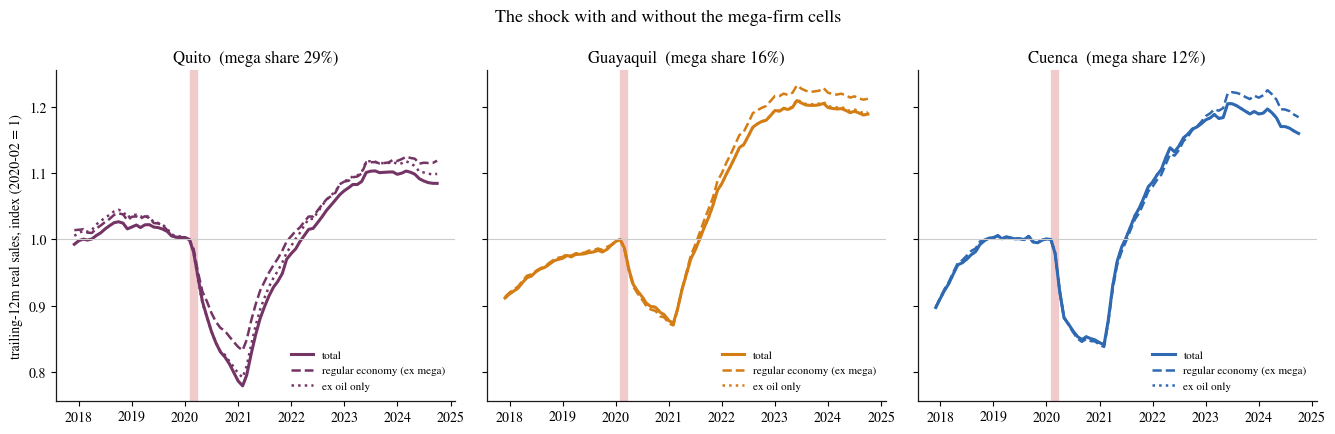

In [14]:
# ==============================================================================
# STEP L -- mega-firm cells, and resilience of the "regular economy"
# ------------------------------------------------------------------------------
# A baseline (T0_YEAR) unit x group cell is flagged "mega" if its sales per
# taxpayer exceed the MEGA_PCT quantile of all baseline cells. Taxpayers = the
# documented top of the cell's range, so sales per taxpayer is a guaranteed
# minimum and the flag errs towards flagging too little. The regular economy
# = all unflagged cells (flag set frozen at baseline, so the series is not
# censored over time). Oil groups are the named special case. Trough/recovery
# machinery from STEP B re-runs unchanged on the regular-economy series.
# ==============================================================================
MEGA_PCT = 0.99
OIL_GRPS = ["B061", "B062", "B091", "C192"]     # crude, gas, oil services, refining

b19 = (fpr[fpr["year"] == T0_YEAR].groupby(["unit", "grp"], observed=True)
       .agg(sales19=("sales", "sum"), tmonths=("max_taxpayers", "sum")))
b19["max_taxpayers19"] = b19["tmonths"] / 12.0   # at most this many, on average over the year
b19["spf"] = b19["sales19"] / b19["max_taxpayers19"]   # AT LEAST this many $ per taxpayer-year
SPF_THR = float(b19["spf"].quantile(MEGA_PCT))
b19["mega"] = b19["spf"] > SPF_THR
mega_cells = b19.index[b19["mega"]]

fl = b19[b19["mega"]]
print(f"mega threshold (P{100*MEGA_PCT:g} of {len(b19):,} baseline cells): "
      f"at least ${SPF_THR/1e6:,.1f}M per taxpayer-year")
print(f"flagged: {len(fl)} cells = {fl['sales19'].sum()/b19['sales19'].sum():.1%} "
      f"of {T0_YEAR} sales")

top_g = (fl.groupby("grp").agg(cells=("sales19", "size"), sales=("sales19", "sum"),
                               max_taxpayers=("max_taxpayers19", "sum")).nlargest(12, "sales"))
top_g.index = [f"{g} {gname(g)}" + (" [oil]" if g in OIL_GRPS else "")
               for g in top_g.index]
print("\nwhat got flagged (top 12 groups by flagged sales, $B):")
print(top_g.assign(sales=lambda d: (d["sales"] / 1e9).round(2),
                   max_taxpayers=lambda d: d["max_taxpayers"].round(0)).to_string())

div["mega_share"] = (fl.groupby("unit")["sales19"].sum()
                     / b19.groupby("unit")["sales19"].sum()).reindex(KEEP).fillna(0.0)
print("\nmega-firm share of baseline sales -- metros:  "
      + "   ".join(f"{lab} {div.loc[u, 'mega_share']:.1%}"
                   for u, lab in METROS.items()))
print("most mega-dominated units:")
print(div.join(res["name"]).nlargest(8, "mega_share")[["name", "mega_share"]]
      .round(3).to_string())

# ---- regular-economy (and oil-free) monthly series -> trough & recovery --------
fpr["mega"] = pd.MultiIndex.from_frame(fpr[["unit", "grp"]]).isin(mega_cells)

def monthly_units(d):
    'unit x month real-sales matrix on the STEP-A month grid'
    return (d.groupby(["unit", "ym"], observed=True)["sales"].sum()
            .unstack("unit").reindex(months).fillna(0.0)
            .reindex(columns=KEEP, fill_value=0.0))

S12_reg = monthly_units(fpr[~fpr["mega"]]).rolling(12, min_periods=12).sum()
S12_oil = monthly_units(fpr[~fpr["grp"].isin(OIL_GRPS)]).rolling(12, min_periods=12).sum()
S12_fin = monthly_units(fpr).rolling(12, min_periods=12).sum()   # fine total, for indexing

assert (S12_reg.loc[BENCH_P] > 0).all(), "a unit lost its whole benchmark to the flag"
res_sr, tr_sr, rec_sr = trough_and_recovery(S12_reg, S12_reg.loc[BENCH_P])
res["res_sales_reg"], res["rec_sales_reg"] = res_sr, rec_sr

print("\n--- the metros: total vs regular economy (trough log pts / months back) ---")
for u, lab in METROS.items():
    print(f"  {lab:10s} total {res.loc[u,'res_sales']:+.3f} / "
          f"{res.loc[u,'rec_sales']:.0f}m   regular {res_sr[u]:+.3f} / "
          f"{'censored' if pd.isna(rec_sr[u]) else f'{rec_sr[u]:.0f}m'}")
pct = lambda c, u: 100 * (res[c] < res.loc[u, c]).mean()
print("resistance percentile, total -> regular:  "
      + "   ".join(f"{lab} {pct('res_sales', u):.0f}% -> {pct('res_sales_reg', u):.0f}%"
                   for u, lab in METROS.items()))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), sharey=True)
for ax, (u, lab) in zip(axes, METROS.items()):
    for X12, ls_, lw_, tag in [(S12_fin, "-", 2.2, "total"),
                               (S12_reg, "--", 1.8, "regular economy (ex mega)"),
                               (S12_oil, ":", 1.8, "ex oil only")]:
        s = (X12[u] / X12.loc[BENCH_P, u]).dropna()
        ax.plot(s.index.to_timestamp(), s.values, ls_, lw=lw_,
                color=METRO_C[lab], label=tag)
    ax.axhline(1.0, color="0.8", lw=0.8)
    ax.axvline(SHOCK_P.to_timestamp(), color=RED_DOT, lw=6, alpha=0.6, zorder=0)
    ax.set_title(f"{lab}  (mega share {div.loc[u, 'mega_share']:.0%})", fontsize=12)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0].set_ylabel(f"trailing-12m real sales, index ({BENCH_P} = 1)", fontsize=10)
fig.suptitle("The shock with and without the mega-firm cells", fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"regular_economy_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"regular_economy_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"regular_economy_{LEVEL}.png")
plt.show()

saved -> results/resilience/regular_vs_total_parish.png


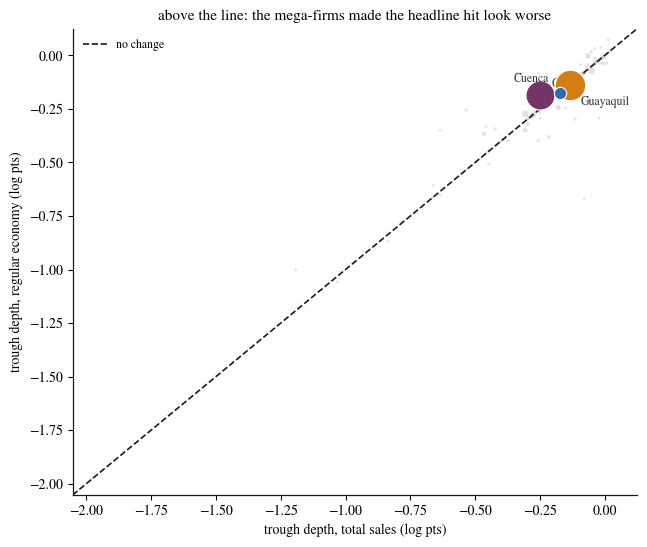

units whose regular economy fell much LESS than their total (mega-firms carried the crash):
                                                     name  res_sales  res_sales_reg    gap
unit                                                                                      
080168                          Vuelta Larga (Esmeraldas)     -0.635         -0.351  0.284
170183                                   Tababela (Quito)     -0.534         -0.255  0.278
170170                                      Nayon (Quito)     -0.336         -0.086  0.250
060650                                  Guamote (Guamote)     -1.191         -1.001  0.190
180152                     Atahualpa (Chisalata) (Ambato)     -0.255         -0.084  0.172
210156                              Pacayacu (Lago Agrio)     -0.459         -0.332  0.127
131450                          Bahia De Caraquez (Sucre)     -0.276         -0.170  0.106
220150  Puerto Francisco De Orellana (El Coca) (Orellana)     -0.466         -0.366  0.10


regular economy, variance of the 2019->2020 hit explained by (group-level) composition: 33.2%
--- the metros, regular economy: actual = composition + own residual ---
  Quito      -0.170 = -0.136 (mix) -0.034 (own)    [total was -0.226]
  Guayaquil  -0.117 = -0.124 (mix) +0.007 (own)    [total was -0.112]
  Cuenca     -0.166 = -0.186 (mix) +0.020 (own)    [total was -0.163]

REGULAR-economy hit ~ composition + diversity + size
  n=174  R2=0.481  (province FE: yes; HC1 SEs)
             Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  -0.0137    0.0792 -0.1725  0.8631 -0.1688  0.1415
bartik_reg  1.0949    0.2229  4.9111  0.0000  0.6580  1.5319
neff       -0.0048    0.0138 -0.3453  0.7298 -0.0318  0.0222
log_firms   0.0045    0.0167  0.2696  0.7874 -0.0282  0.0371

REGULAR-economy recovery ~ composition + diversity + size
  n=169  R2=0.349  (province FE: yes; HC1 SEs)
              Coef.  Std.Err.       z   P>|z|   [0.025   0.975]
Intercept   12.0415    3.7829  3.1832  0.0015 

In [15]:
# ==============================================================================
# STEP L (cont.) -- does the story survive the mega-firm filter?
# ------------------------------------------------------------------------------
# (1) every unit: total vs regular-economy trough (above the diagonal = the
#     regular economy fell less than the headline number says);
# (2) the STEP-C diversity correlations re-run on regular outcomes;
# (3) the STEP-D Bartik regression re-run with a group-level leave-one-out
#     Bartik built from the regular-economy panel.
# ==============================================================================
fig, ax = plt.subplots(figsize=(6.6, 5.6))
d = res.dropna(subset=["res_sales", "res_sales_reg"])
lo = min(d["res_sales"].quantile(0.005), d["res_sales_reg"].quantile(0.005)) - 0.05
hi = max(d["res_sales"].max(), d["res_sales_reg"].max()) + 0.05
ax.plot([lo, hi], [lo, hi], color="0.1", lw=1.2, ls="--", label="no change")
ax.scatter(d["res_sales"], d["res_sales_reg"], s=dot_area(d["p0"]),
           color=GRAY_DOT, alpha=0.55, lw=0)
mark_metros(ax, d["res_sales"], d["res_sales_reg"], d["p0"])
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("trough depth, total sales (log pts)", fontsize=10)
ax.set_ylabel("trough depth, regular economy (log pts)", fontsize=10)
ax.set_title("above the line: the mega-firms made the headline hit look worse",
             fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
fig.tight_layout()
fig.savefig(RES_DIR / f"regular_vs_total_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"regular_vs_total_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"regular_vs_total_{LEVEL}.png")
plt.show()

gap = res["res_sales_reg"] - res["res_sales"]
print("units whose regular economy fell much LESS than their total "
      "(mega-firms carried the crash):")
print(res.assign(gap=gap).nlargest(8, "gap")
      [["name", "res_sales", "res_sales_reg", "gap"]].round(3).to_string())

print("\ndiversity vs REGULAR-economy outcomes (STEP-C convention: res + = fell "
      "less; rec - = faster back):")
rows = []
for tag in ["sales", "firms"]:
    neff = div[f"neff_{tag}"]
    for metric in ["res_sales_reg", "rec_sales_reg"]:
        y, m_ = res[metric], res[metric].notna()
        rows.append(dict(
            diversity=f"neff_{tag}", outcome=metric, n=int(m_.sum()),
            spearman=float(sps.spearmanr(neff[m_], y[m_]).statistic),
            pearson=float(sps.pearsonr(neff[m_], y[m_]).statistic),
            pearson_sizectrl=partial_r(neff, y, log_firms0)))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- group-level leave-one-out Bartik on the regular-economy panel -------------
def annual_units_by_grp(d, y):
    return (d[d["year"] == y].groupby(["unit", "grp"], observed=True)["sales"]
            .sum().unstack(fill_value=0.0)
            .reindex(KEEP).fillna(0.0))

regd = fpr[~fpr["mega"]]
Y19r, Y20r = annual_units_by_grp(regd, SHOCK_Y0), annual_units_by_grp(regd, SHOCK_Y1)
grps = Y19r.columns.union(Y20r.columns)
Y19r, Y20r = (Y19r.reindex(columns=grps, fill_value=0.0),
              Y20r.reindex(columns=grps, fill_value=0.0))
S19r, S20r = Y19r.sum(), Y20r.sum()
g_all_r = np.log(S20r.where(S20r > 0) / S19r.where(S19r > 0))
numr, denr = S20r - Y20r, S19r - Y19r
g_loo_r = np.log(numr.where(numr > 0) / denr.where(denr > 0))
g_loo_r = g_loo_r.fillna(g_all_r).fillna(0.0)
w19r = Y19r.div(Y19r.sum(axis=1), axis=0)
bartik_reg = (w19r * g_loo_r).sum(axis=1)
t19, t20 = Y19r.sum(axis=1), Y20r.sum(axis=1)
actual_reg = np.log(t20.where(t20 > 0) / t19.where(t19 > 0))
residual_reg = actual_reg - bartik_reg
print(f"\nregular economy, variance of the {SHOCK_Y0}->{SHOCK_Y1} hit explained "
      f"by (group-level) composition: {1 - residual_reg.var() / actual_reg.var():.1%}")
print("--- the metros, regular economy: actual = composition + own residual ---")
for u, lab in METROS.items():
    print(f"  {lab:10s} {actual_reg[u]:+.3f} = {bartik_reg[u]:+.3f} (mix) "
          f"{residual_reg[u]:+.3f} (own)    [total was {res.loc[u,'dln_sales']:+.3f}]")

reg["actual_reg"] = actual_reg
reg["bartik_reg"] = bartik_reg
reg["rec_reg"]    = res["rec_sales_reg"]
m7 = show_ols("actual_reg ~ bartik_reg + neff + log_firms" + fe,
              ["actual_reg", "bartik_reg", "neff", "log_firms", "prov"],
              "REGULAR-economy hit ~ composition + diversity + size")
m8 = show_ols("rec_reg ~ bartik_reg + neff + log_firms" + fe,
              ["rec_reg", "bartik_reg", "neff", "log_firms", "prov"],
              "REGULAR-economy recovery ~ composition + diversity + size")

## FRAMING 8 — related vs unrelated variety: decomposing entropy along the CIIU tree (STEP M)

FRAMING 2 measured diversity as entropy over 21 sections and found nothing once size was controlled. But entropy over coarse bins conflates two very different kinds of diversity. Because the 239 fine groups nest inside the sections, each unit's group-level entropy **decomposes exactly** (Theil; Frenken, Van Oort & Verburg 2007). With $s_{ig}$ = unit $i$'s baseline share of group $g$, section shares $s_{ia}=\sum_{g\in a}s_{ig}$:

$$\underbrace{-\sum_g s_{ig}\ln s_{ig}}_{H_i\ \text{(group-level entropy)}}\;=\;\underbrace{-\sum_a s_{ia}\ln s_{ia}}_{UV_i\ \text{unrelated variety (between sections)}}\;+\;\underbrace{\sum_a s_{ia}\Big(-\sum_{g\in a}\tfrac{s_{ig}}{s_{ia}}\ln\tfrac{s_{ig}}{s_{ia}}\Big)}_{RV_i\ \text{related variety (within sections)}}$$

- **Unrelated variety** $UV$ — spread across sections that share little (agriculture vs finance vs construction). This is the **portfolio-insurance** channel: sector-specific shocks average out, so $UV$ should buy **resistance**.
- **Related variety** $RV$ — many distinct niches *inside* each section (a manufacturing base spanning food, chemicals, metals). Related activities share inputs, skills and customers, so this is the **adaptability** channel: capacity to recombine and shift within an industry, which should buy **recovery** and show up in the Bartik **residual** rather than in composition.

The identity $H = UV + RV$ is asserted below to machine precision, on sales shares. The section-level $N^{\text{eff}}$ of FRAMING 2 mixed these two channels into one number; if they pull in opposite directions (insurance vs adaptation), that alone can produce the null we found. The tests re-run with $UV$ and $RV$ separately, against both the headline outcomes and the regular-economy outcomes of STEP L — the cleanest version of the diversification question this data can ask.

entropy additivity H = UV + RV holds to machine precision (asserted)

resolution gain: median effective activities, 21 sections 3.8 -> 239 groups 7.4

--- the metros ---
                                                                                                             name  neff_grp_sales  uv_sales  rv_sales
unit                                                                                                                                                 
170150  Quito Distrito Metropolitano, Cabecera Cantonal, Capital Provincial Y De La Republica Del Ecuador (Quito)          58.439     2.099     1.969
090150                                                                                      Guayaquil (Guayaquil)          60.185     1.902     2.195
010150                                                                                            Cuenca (Cuenca)          43.372     1.664     2.106

variety vs resilience (res + = fell less; rec - = faster back):
 variety       

saved -> results/resilience/variety_decomposition_parish.png


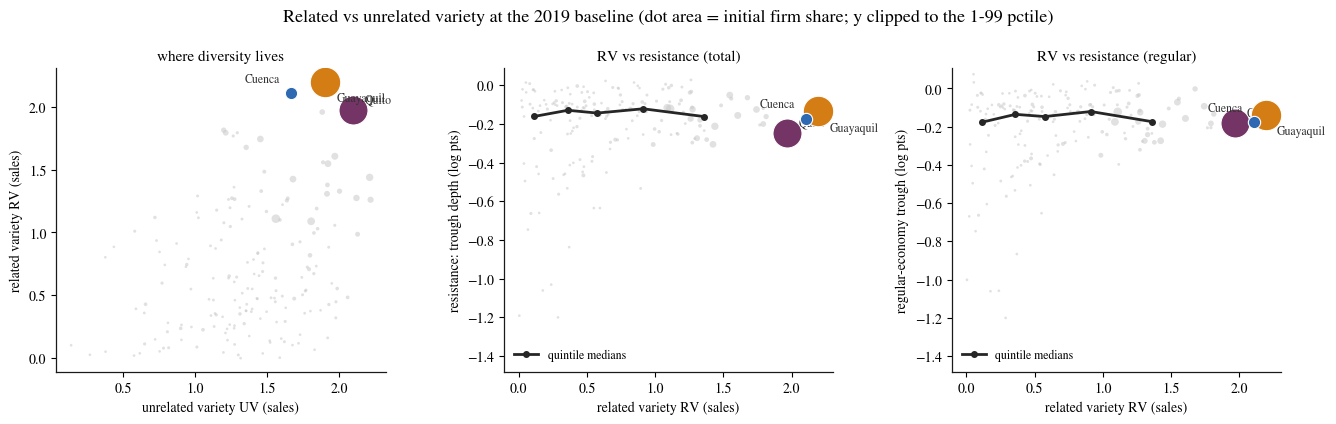


actual hit ~ composition + UV + RV + size
  n=174  R2=0.516  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  0.1487    0.0842  1.7669  0.0772 -0.0163  0.3137
bartik     2.0087    0.4077  4.9272  0.0000  1.2097  2.8078
uv         0.0184    0.0484  0.3793  0.7045 -0.0766  0.1133
rv        -0.0145    0.0443 -0.3285  0.7425 -0.1013  0.0722
log_firms  0.0034    0.0189  0.1812  0.8562 -0.0336  0.0404

Bartik residual ~ UV + RV + size
  n=174  R2=0.372  (province FE: yes; HC1 SEs)
            Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
Intercept  0.0089    0.0641  0.1384  0.8899 -0.1168  0.1345
uv        -0.0259    0.0438 -0.5898  0.5553 -0.1118  0.0601
rv        -0.0178    0.0427 -0.4170  0.6767 -0.1015  0.0659
log_firms  0.0132    0.0177  0.7477  0.4546 -0.0215  0.0479

recovery months ~ composition + UV + RV + size
  n=168  R2=0.302  (province FE: yes; HC1 SEs)
             Coef.  Std.Err.       z   P>|z|   [0.025   0.975]
Intercept  

In [16]:
# ==============================================================================
# STEP M -- related vs unrelated variety at the baseline, and the sharper test
# ------------------------------------------------------------------------------
# Variety measured on ALL baseline cells (mega included: they are part of the
# structure); outcomes tested on both the total and the regular economy.
# uv/rv computed on sales shares (the only variable documented at group level).
# Additivity asserted.
# ==============================================================================
W19g = b19["sales19"].unstack(fill_value=0.0).reindex(KEEP).fillna(0.0)

def H_of(sh):
    return -(sh * np.log(sh.where(sh > 0))).sum(axis=1)

def variety(comp, tag):
    'group entropy H = UV (between sections) + RV (within); plus exp(H)'
    sh = comp.div(comp.sum(axis=1), axis=0)
    H = H_of(sh)
    sec = sh.T.groupby(sh.columns.str[0]).sum().T
    UV = H_of(sec)
    RV = H - UV
    within = pd.Series(0.0, index=sh.index)          # explicit within-sum check
    for a in sec.columns:
        cols = [c for c in sh.columns if c[0] == a]
        cond = sh[cols].div(sec[a].where(sec[a] > 0), axis=0)
        within = within + (sec[a] * H_of(cond)).fillna(0.0)
    assert (H - UV - within).abs().max() < 1e-9, "entropy decomposition broken"
    return pd.DataFrame({f"H_grp_{tag}": H, f"neff_grp_{tag}": np.exp(H),
                         f"uv_{tag}": UV, f"rv_{tag}": RV})

for vt in [variety(W19g, "sales")]:
    div[vt.columns] = vt                    # assignment, so the cell can re-run
print("entropy additivity H = UV + RV holds to machine precision (asserted)")
print(f"\nresolution gain: median effective activities, 21 sections "
      f"{div['neff_sales'].median():.1f} -> 239 groups {div['neff_grp_sales'].median():.1f}")
print("\n--- the metros ---")
print(div.join(res["name"]).loc[list(METROS),
      ["name", "neff_grp_sales", "uv_sales", "rv_sales"]]
      .round(3).to_string())

rows = []
for meas in ["uv_sales", "rv_sales"]:
    for metric in ["res_sales", "rec_sales", "res_sales_reg", "rec_sales_reg"]:
        y, m_ = res[metric], res[metric].notna()
        rows.append(dict(
            variety=meas, outcome=metric, n=int(m_.sum()),
            spearman=float(sps.spearmanr(div[meas][m_], y[m_]).statistic),
            pearson=float(sps.pearsonr(div[meas][m_], y[m_]).statistic),
            pearson_sizectrl=partial_r(div[meas], y, log_firms0)))
print("\nvariety vs resilience (res + = fell less; rec - = faster back):")
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
panels = [(div["uv_sales"], div["rv_sales"], "unrelated variety UV (sales)",
           "related variety RV (sales)", "where diversity lives", False),
          (div["rv_sales"], res["res_sales"], "related variety RV (sales)",
           "resistance: trough depth (log pts)", "RV vs resistance (total)", True),
          (div["rv_sales"], res["res_sales_reg"], "related variety RV (sales)",
           "regular-economy trough (log pts)", "RV vs resistance (regular)", True)]
for ax, (x, y, xl, yl, ttl, clip_y) in zip(axes, panels):
    m_ = x.notna() & y.notna()
    ax.scatter(x[m_], y[m_], s=dot_area(res.loc[m_[m_].index, "p0"]),
               color=GRAY_DOT, alpha=0.55, lw=0)
    if ttl != "where diversity lives":
        bx, by = binned_median(x[m_], y[m_])
        ax.plot(bx, by, color="0.15", lw=2.0, marker="o", ms=4,
                label="quintile medians")
        ax.legend(frameon=False, fontsize=8.5, loc="best")
    mark_metros(ax, x[m_], y[m_], res["p0"])
    if clip_y:
        lo, hi = np.nanpercentile(y[m_], [1, 99])
        pad = 0.05 * (hi - lo)
        ax.set_ylim(lo - pad, hi + pad)          # display clip; table keeps all
    ax.set_xlabel(xl, fontsize=10); ax.set_ylabel(yl, fontsize=10)
    ax.set_title(ttl, fontsize=11)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
fig.suptitle(f"Related vs unrelated variety at the {T0_YEAR} baseline "
             "(dot area = initial firm share; y clipped to the 1-99 pctile)",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"variety_decomposition_{LEVEL}.png", dpi=200,
            bbox_inches="tight")
fig.savefig(RES_DIR / f"variety_decomposition_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"variety_decomposition_{LEVEL}.png")
plt.show()

# ---- the regressions: UV and RV replace the single neff -------------------------
reg["uv"], reg["rv"] = div["uv_sales"], div["rv_sales"]
m9  = show_ols("actual ~ bartik + uv + rv + log_firms" + fe,
               ["actual", "bartik", "uv", "rv", "log_firms", "prov"],
               "actual hit ~ composition + UV + RV + size")
m10 = show_ols("residual ~ uv + rv + log_firms" + fe,
               ["residual", "uv", "rv", "log_firms", "prov"],
               "Bartik residual ~ UV + RV + size")
m11 = show_ols("recovery ~ bartik + uv + rv + log_firms" + fe,
               ["recovery", "bartik", "uv", "rv", "log_firms", "prov"],
               "recovery months ~ composition + UV + RV + size")
m12 = show_ols("actual_reg ~ bartik_reg + uv + rv + log_firms" + fe,
               ["actual_reg", "bartik_reg", "uv", "rv", "log_firms", "prov"],
               "REGULAR-economy hit ~ composition + UV + RV + size")
m13 = show_ols("rec_reg ~ bartik_reg + uv + rv + log_firms" + fe,
               ["rec_reg", "bartik_reg", "uv", "rv", "log_firms", "prov"],
               "REGULAR-economy recovery ~ composition + UV + RV + size")
print("\nreading: the insurance story needs uv > 0 in the hit models; the "
      "adaptation story needs rv < 0 in the recovery models (fewer months) "
      "and rv > 0 in the residual model.")

## FRAMING 9 — where Ecuador's diversity lives: within or between parishes (STEP N)

The same additivity that split $H$ into $UV+RV$ along the *sectoral* tree splits national diversity along the *spatial* tree. With $p(i,g)$ = parish $i$ × group $g$'s share of national sales, $q_i$ its parish total and $H_i$ its internal group entropy:

$$\underbrace{H(G)}_{\text{national sectoral entropy}}\;=\;\underbrace{\textstyle\sum_i q_i\,H_i}_{\text{mean within-parish diversity}}\;+\;\underbrace{I(P;G)}_{\text{between: spatial specialization}}$$

$I(P;G)$ is the mutual information between place and sector — how much knowing *where* tells you *what*: zero if every parish is a miniature of the national mix, large if places specialize. Tracked year by year through the shock, this asks the multiscale question directly: **did COVID make Ecuador's economy more spatially specialized** (killing the off-mix activities parishes had, raising $I$) **or more homogeneous** — and did the diversity that survived live *inside* parishes or in the *differences between* them? A purely descriptive complement to framings 7–8, on the sales margin.

national group-entropy split, by year:
           H_G  within between
margin   sales   sales   sales
year                          
2017    4.3494  3.6524  0.6970
2018    4.3413  3.6453  0.6959
2019    4.3339  3.6374  0.6965
2020    4.3014  3.5975  0.7039
2021    4.2921  3.5816  0.7106
2022    4.2859  3.5819  0.7040
2023    4.3085  3.6147  0.6938


saved -> results/resilience/spatial_entropy_parish.png


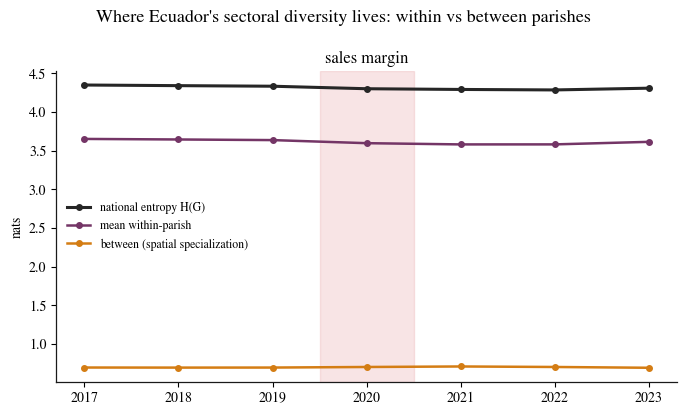

saved -> results/resilience/resilience_metrics_parish.csv   (174 units x 35 columns)


In [17]:
# ==============================================================================
# STEP N -- national entropy = mean within-parish + between (mutual information)
# ------------------------------------------------------------------------------
# Complete years only. p(i,g) from the fine panel over kept units; identity
# H(G) = sum_i q_i H_i + I(P;G) is exact (asserted). Sales margin.
# The merged metrics CSV is re-saved at the end with every new column.
# ==============================================================================
rowsN = []
for y in FULL_YEARS:
    d = fpr[fpr["year"] == y]
    for margin in ["sales"]:
        X = (d.groupby(["unit", "grp"], observed=True)[margin].sum()
             .astype(float).unstack(fill_value=0.0))
        q = X.sum(axis=1) / X.values.sum()
        pg = X.sum(axis=0) / X.values.sum()
        H_G = float(-(pg * np.log(pg.where(pg > 0))).sum())
        within = float((q * H_of(X.div(X.sum(axis=1), axis=0))).sum())
        rowsN.append(dict(year=y, margin=margin, H_G=H_G,
                          within=within, between=H_G - within))
entN = pd.DataFrame(rowsN)
assert (entN["between"] >= -1e-12).all(), "mutual information must be >= 0"
print("national group-entropy split, by year:")
print(entN.pivot(index="year", columns="margin",
                 values=["H_G", "within", "between"]).round(4).to_string())

fig, ax = plt.subplots(figsize=(7.0, 4.2))
axes = [ax]
for ax, margin in zip(axes, ["sales"]):
    e = entN[entN["margin"] == margin].set_index("year")
    ax.axvspan(SHOCK_Y1 - 0.5, SHOCK_Y1 + 0.5, color=RED_DOT, alpha=0.30, zorder=0)
    ax.plot(e.index, e["H_G"], color="0.15", lw=2.2, marker="o", ms=4,
            label="national entropy H(G)")
    ax.plot(e.index, e["within"], color=CUSTOM_PURPLE, lw=1.8, marker="o", ms=4,
            label="mean within-parish")
    ax.plot(e.index, e["between"], color=CUSTOM_ORANGE, lw=1.8, marker="o", ms=4,
            label="between (spatial specialization)")
    ax.set_title(f"{margin} margin", fontsize=12)
    ax.set_xticks(FULL_YEARS)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0].set_ylabel("nats", fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, loc="center left")
fig.suptitle("Where Ecuador's sectoral diversity lives: within vs between parishes",
             fontsize=13)
fig.tight_layout()
fig.savefig(RES_DIR / f"spatial_entropy_{LEVEL}.png", dpi=200, bbox_inches="tight")
fig.savefig(RES_DIR / f"spatial_entropy_{LEVEL}.pdf", bbox_inches="tight")
print("saved ->", RES_DIR / f"spatial_entropy_{LEVEL}.png")
plt.show()

# ---- final export: everything, framings 1-9 -------------------------------------
merged = res.join(div).join(pd.DataFrame({
    "bartik": bartik, "bartik_residual": residual,
    "actual_reg": actual_reg, "bartik_reg": bartik_reg,
    "bartik_residual_reg": residual_reg}))
out = RES_DIR / f"resilience_metrics_{LEVEL}.csv"
merged.to_csv(out, encoding="utf-8-sig")
print(f"saved -> {out}   ({merged.shape[0]} units x {merged.shape[1]} columns)")